# FarmTech Neural Vision — Fase 6
## Entrega 2 — Comparação de modelos de visão computacional

### Objetivo
Avaliar três abordagens utilizando o dataset de banana e milho:

1. YOLOv5 customizada — modelo desenvolvido na Entrega 1.
2. YOLO padrão — modelo pré-treinado, sem customização.
3. CNN treinada do zero — implementada, treinada e avaliada neste notebook para classificação de banana e milho.

### Critérios de avaliação
- Precisão dos modelos.
- Tempo de treinamento ou preparação.
- Tempo de inferência.
- Facilidade de uso e integração.

### Metodologia

Os pesos originais e os resultados experimentais da YOLOv5s customizada, desenvolvida na Entrega 1, foram recuperados. O modelo de 60 épocas foi carregado e avaliado no conjunto de teste, permitindo complementar a comparação quantitativa com a YOLO padrão e a CNN treinada do zero.

A YOLOv5s padrão será avaliada utilizando seus pesos pré-treinados, sem customização para o dataset do projeto.

A CNN será implementada, treinada e avaliada neste notebook, utilizando as imagens de banana e milho.

A comparação considerará as diferenças entre detecção de objetos e classificação de imagens, bem como as condições experimentais, as métricas obtidas e as limitações metodológicas de cada abordagem.


Como detecção de objetos e classificação de imagens são tarefas diferentes, suas métricas serão apresentadas e interpretadas respeitando essas diferenças.

**Dataset:** 80 imagens, divididas em 64 para treinamento, 8 para validação e 8 para teste.

### Modos de leitura e avaliação após a auditoria de 03/11/2026

Este notebook preserva os experimentos históricos, incluindo código, contagens de execução e saídas. As células experimentais estão protegidas por blocos `if False`: executar o notebook para consulta não inicia treinamento, carrega modelos ou grava checkpoints. As saídas dessas células são registros anteriores às proteções, não resultados de uma nova execução.

A preparação atual limita-se à inspeção das dependências já instaladas. A avaliação de modelos preservados é um procedimento independente, descrito na seção 8, em processos novos e sem executar as células históricas. A validação funcional dos novos procedimentos ainda não foi realizada.

In [2]:
from pathlib import Path
import sys

# Localizar o dataset da Fase 6
pasta_atual = Path.cwd()

candidatos = [
    pasta_atual / "dataset",
    pasta_atual.parent / "dataset"
]

DATASET = next((p for p in candidatos if p.is_dir()), None)

print("Python:", sys.version.split()[0])
print("Ambiente:", sys.executable)
print("Dataset:", DATASET)

if DATASET is None:
    raise FileNotFoundError("Dataset da Fase 6 não encontrado.")

for conjunto in ["train", "val", "test"]:
    for classe in ["banana", "milho"]:
        pasta = DATASET / conjunto / "images" / classe
        quantidade = len(list(pasta.glob("*.jpg")))
        print(f"{conjunto} | {classe}: {quantidade} imagens")

Python: 3.13.13
Ambiente: c:\Users\Georgia\Desktop\farmtech-integracao\servicos\fase6-visao\.venv-fase6\Scripts\python.exe
Dataset: c:\Users\Georgia\Desktop\farmtech-integracao\servicos\fase6-visao\dataset
train | banana: 32 imagens
train | milho: 32 imagens
val | banana: 4 imagens
val | milho: 4 imagens
test | banana: 4 imagens
test | milho: 4 imagens



### 1. Verificação do ambiente e integridade inicial do dataset

**Objetivo:** identificar o ambiente de execução e verificar a disponibilidade das imagens utilizadas nos experimentos.

**Procedimento:**

O código utiliza a biblioteca `pathlib` para localizar o diretório `dataset`, considerando tanto a pasta de execução quanto seu diretório superior. Em seguida, identifica a versão do Python e contabiliza as imagens de cada classe nos conjuntos de treinamento, validação e teste.

**Resultados da execução:**

- Python desta verificação: 3.13.13.
- Classes: banana e milho.
- Treinamento: 64 imagens (32 por classe).
- Validação: 8 imagens (4 por classe).
- Teste: 8 imagens (4 por classe).
- Total: 80 imagens.

**Interpretação:**

A distribuição encontrada está de acordo com as quantidades exigidas no enunciado da Fase 6, mantendo conjuntos separados para treinamento, validação e teste.

A separação permite avaliar os modelos em imagens não utilizadas durante o treinamento.

**Limitação desta verificação:**

Esta etapa confirma a quantidade e a localização dos arquivos `.jpg`, mas não avalia a qualidade das imagens, a correspondência com os arquivos de rotulação nem possíveis duplicações entre os conjuntos. Esses aspectos exigem verificações específicas.


In [2]:
# Preparacao atual: consulta somente dependencias ja instaladas.
# A saida preservada desta celula pertence ao antigo %pip install ultralytics.
from importlib.metadata import PackageNotFoundError, version

for pacote in ("tensorflow", "keras", "torch", "torchvision", "ultralytics", "numpy", "opencv-python", "matplotlib", "Pillow"):
    try:
        print(f"{pacote}: {version(pacote)}")
    except PackageNotFoundError:
        print(f"{pacote}: ausente; preparar o ambiente separadamente, sem instalar nesta avaliacao.")


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


### 2. Preparação do ambiente e das dependências

**Objetivo**

Verificar a disponibilidade das bibliotecas necessárias à execução dos modelos YOLO e preparar o ambiente para os experimentos de visão computacional.

**Procedimento**

Na preparação histórica foi utilizado `%pip install ultralytics`. A célula de preparação atual apenas consulta os metadados das dependências instaladas; o comando de instalação não permanece ativo. A saída de instalação foi preservada como evidência histórica.

Entre as principais dependências estão PyTorch, OpenCV e NumPy, utilizadas para processamento de imagens, operações numéricas e inferência com redes neurais.

**Resultados da execução**

Na execução registrada, a biblioteca Ultralytics já estava disponível na versão 8.4.173. Durante o carregamento posterior da YOLOv5s pelo PyTorch Hub, ocorreu uma atualização automática para a versão 8.4.198.

Essa preparação histórica e o carregamento da YOLOv5s padrão registram Python 3.14.4, com processamento em CPU. A verificação inicial atual e as etapas da CNN e da YOLO customizada registram Python 3.13.13. Essas execuções não devem ser apresentadas como um único ambiente.

**Reprodutibilidade**

A preparação de outro computador é uma etapa separada da avaliação. As versões do ambiente complementar estão em `../requirements.txt`. Os procedimentos independentes exigem dependências, pesos e, para YOLO, código local já disponíveis; não instalam pacotes nem obtêm modelos durante a avaliação.

As versões das bibliotecas, o hardware e as condições de execução devem ser considerados na reprodução dos experimentos, especialmente nas comparações de desempenho computacional.

**Considerações técnicas**

Esta etapa verifica as dependências do ambiente. Não realiza treinamento nem avaliação dos modelos.

O desempenho das arquiteturas será analisado nas seções experimentais, utilizando métricas, parâmetros e resultados documentados.

In [3]:
# Registro historico protegido; nenhuma execucao de modelo neste fluxo.
# Avaliacao independente: procedimentos da secao 8, em processo novo.
if False:
    from ultralytics import YOLO

    # Modelo pré-treinado, sem treinamento com banana e milho
    modelo_padrao = YOLO("yolov5su.pt")

    print("Modelo carregado com sucesso.")
    print("Classes relacionadas ao projeto:")

    for indice, nome in modelo_padrao.names.items():
        if nome.lower() in ["banana", "corn", "milho"]:
            print(f"{indice}: {nome}")
else:
    print("Registro historico preservado; use o procedimento independente da secao 8.")


Modelo carregado com sucesso.
Classes relacionadas ao projeto:
46: banana



### 3. Experimento exploratório — YOLOv5u pré-treinada

**Objetivo**

Verificar o funcionamento de um modelo YOLO pré-treinado, sem adaptação ao dataset da FarmTech Neural Vision, e estabelecer uma referência exploratória para os experimentos de detecção.

**Metodologia**

Foi utilizada a YOLOv5u, disponibilizada pela biblioteca Ultralytics, com pesos pré-treinados armazenados no arquivo `yolov5su.pt`.

O modelo foi carregado sem treinamento adicional. A primeira execução realizou o download automático dos pesos.

Em seguida, foram consultadas as classes disponíveis para identificar aquelas relacionadas ao conjunto de imagens utilizado no projeto.

**Resultados**

O modelo foi carregado com sucesso e identificou-se a classe `banana`, associada ao índice 46.

**Considerações técnicas**

A YOLOv5u é uma variante atualizada da arquitetura YOLOv5. Portanto, seus resultados serão tratados como experimentação complementar.

Para a comparação principal exigida no enunciado, será utilizada a YOLOv5s original pré-treinada, correspondente à arquitetura empregada na Entrega 1.

Esta etapa confirma o carregamento do modelo e a disponibilidade de suas classes, sem constituir ainda uma avaliação de precisão ou desempenho.


In [4]:
# Registro historico protegido; nenhuma execucao de modelo neste fluxo.
# Avaliacao independente: procedimentos da secao 8, em processo novo.
if False:
    imagem = DATASET / "test" / "images" / "banana" / "banana_02.jpg"

    resultados = modelo_padrao.predict(
        source=str(imagem),
        imgsz=640,
        conf=0.25,
        verbose=False
    )

    resultado = resultados[0]

    print("Imagem:", imagem.name)

    if len(resultado.boxes) == 0:
        print("Nenhum objeto detectado.")
    else:
        for caixa in resultado.boxes:
            classe = int(caixa.cls[0])
            confianca = float(caixa.conf[0])
            print(f"Objeto: {resultado.names[classe]} | Confiança: {confianca:.2%}")

    print("Tempo de inferência:", round(sum(resultado.speed.values()), 2), "ms")
else:
    print("Registro historico preservado; use o procedimento independente da secao 8.")


Imagem: banana_02.jpg
Objeto: banana | Confiança: 83.29%
Objeto: banana | Confiança: 81.40%
Objeto: banana | Confiança: 80.45%
Objeto: banana | Confiança: 80.20%
Objeto: banana | Confiança: 74.61%
Objeto: banana | Confiança: 60.33%
Objeto: banana | Confiança: 38.45%
Tempo de inferência: 264.76 ms



### 3.1. Teste inicial de detecção — imagem banana_02.jpg

**Objetivo**

Verificar a capacidade da YOLOv5u pré-treinada de localizar objetos em uma imagem do conjunto de teste, sem treinamento adicional.

**Procedimento**

Foi utilizada a imagem `banana_02.jpg`, pertencente ao conjunto de teste da classe banana.

A inferência foi realizada com resolução de 640 pixels e limiar mínimo de confiança de 0,25.

Foram registrados os nomes das classes identificadas, os níveis de confiança das previsões e o tempo de processamento informado pelo modelo.

**Resultados**

O modelo produziu sete detecções da classe `banana`, com níveis de confiança entre 38,45% e 83,29%.

O tempo registrado foi de 264,76 milissegundos, considerando a soma dos tempos de pré-processamento, inferência e pós-processamento.

**Interpretação crítica**

A identificação da classe esperada demonstra que o modelo possui capacidade de reconhecer bananas sem treinamento específico com as imagens da FarmTech.

Entretanto, a quantidade de detecções não corresponde necessariamente à quantidade de objetos corretamente localizados. Diferentes caixas podem representar detecções redundantes de um mesmo objeto.

Os níveis de confiança também não devem ser interpretados como medidas de precisão ou acurácia.

Por isso, a avaliação quantitativa será realizada mediante comparação das caixas previstas com as anotações originais, utilizando o índice de interseção sobre união (IoU).

O tempo observado corresponde a uma execução individual e não constitui, isoladamente, uma medida representativa do desempenho computacional do modelo.


In [5]:
# Registro historico protegido; nenhuma execucao de modelo neste fluxo.
# Avaliacao independente: procedimentos da secao 8, em processo novo.
if False:
    tempos = []
    acertos_banana = 0
    falsos_positivos_milho = 0

    for classe_real in ["banana", "milho"]:
        pasta = DATASET / "test" / "images" / classe_real

        for imagem in sorted(pasta.glob("*.jpg")):
            resultado = modelo_padrao.predict(
                source=str(imagem),
                imgsz=640,
                conf=0.25,
                verbose=False
            )[0]

            classes_detectadas = [
                resultado.names[int(c)]
                for c in resultado.boxes.cls.tolist()
            ]

            encontrou_banana = "banana" in classes_detectadas
            tempo = resultado.speed["inference"]
            tempos.append(tempo)

            if classe_real == "banana" and encontrou_banana:
                acertos_banana += 1

            if classe_real == "milho" and encontrou_banana:
                falsos_positivos_milho += 1

            print(
                f"{imagem.name} | "
                f"banana detectada: {encontrou_banana} | "
                f"classes: {classes_detectadas} | "
                f"inferência: {tempo:.1f} ms"
            )

    print("\nRESUMO")
    print(f"Imagens de banana detectadas: {acertos_banana}/4")
    print(f"Imagens de milho com falsa detecção de banana: {falsos_positivos_milho}/4")
    print(f"Tempo médio de inferência: {sum(tempos)/len(tempos):.2f} ms/imagem")
else:
    print("Registro historico preservado; use o procedimento independente da secao 8.")


banana_01.jpg | banana detectada: False | classes: ['vase'] | inferência: 213.8 ms
banana_02.jpg | banana detectada: True | classes: ['banana', 'banana', 'banana', 'banana', 'banana', 'banana', 'banana'] | inferência: 139.0 ms
banana_03.jpg | banana detectada: True | classes: ['banana'] | inferência: 307.6 ms
banana_04.jpg | banana detectada: True | classes: ['banana'] | inferência: 1071.6 ms
milho_01.jpg | banana detectada: False | classes: [] | inferência: 186.9 ms
milho_02.jpg | banana detectada: False | classes: ['dining table'] | inferência: 171.2 ms
milho_03.jpg | banana detectada: False | classes: [] | inferência: 109.1 ms
milho_04.jpg | banana detectada: False | classes: ['hot dog'] | inferência: 116.5 ms

RESUMO
Imagens de banana detectadas: 3/4
Imagens de milho com falsa detecção de banana: 0/4
Tempo médio de inferência: 289.47 ms/imagem



### 3.2. Avaliação preliminar da YOLOv5u no conjunto de teste

**Objetivo**

Investigar o comportamento da YOLOv5u pré-treinada nas oito imagens de teste da FarmTech Neural Vision, verificando a ocorrência de detecções da classe banana.

**Metodologia**

Foram processadas quatro imagens de banana e quatro imagens de milho, mantendo os seguintes parâmetros:

- Resolução de entrada: 640 pixels.
- Confiança mínima: 0,25.
- Modelo: YOLOv5u pré-treinada, sem customização.
- Ambiente de execução: CPU.

Para cada imagem, foram registradas as classes detectadas, a presença ou ausência de detecções de banana e o tempo de inferência informado pelo modelo.

**Resultados obtidos**

| Indicador | Resultado |
|---|---|
| Imagens de banana com pelo menos uma detecção da classe | 3 de 4 (75%) |
| Imagens de milho com detecção da classe banana | 0 de 4 |
| Tempo médio de inferência | 289,47 ms/imagem |

A imagem `banana_01.jpg` não apresentou detecção de banana. A imagem `banana_02.jpg` apresentou sete detecções dessa classe, enquanto `banana_03.jpg` e `banana_04.jpg` apresentaram uma detecção cada.

O tempo de inferência variou entre 109,1 ms e 1.071,6 ms, evidenciando variação significativa entre as execuções.

**Interpretação crítica**

O modelo identificou a classe banana em três das quatro imagens correspondentes, demonstrando capacidade de reconhecimento sem treinamento adicional com o dataset do projeto.

Entretanto, a detecção da classe esperada em uma imagem não comprova a localização correta de todos os objetos presentes.

A taxa de 75% representa a proporção de imagens de banana com pelo menos uma detecção dessa classe. Não deve ser confundida com Precision, Recall, mAP ou acurácia de classificação.

A ausência de detecções de banana nas quatro imagens de milho também não comprova, isoladamente, desempenho adequado na detecção dessa cultura.

A variação nos tempos de inferência exige cautela na análise de eficiência computacional, especialmente diante do número reduzido de imagens e da execução em CPU.

**Encaminhamento experimental**

A próxima avaliação utilizará as anotações originais do dataset para verificar a correspondência espacial entre as caixas previstas e os objetos rotulados, por meio do índice IoU.

Isso permitirá calcular métricas de detecção mais adequadas para interpretar os resultados da YOLOv5u.


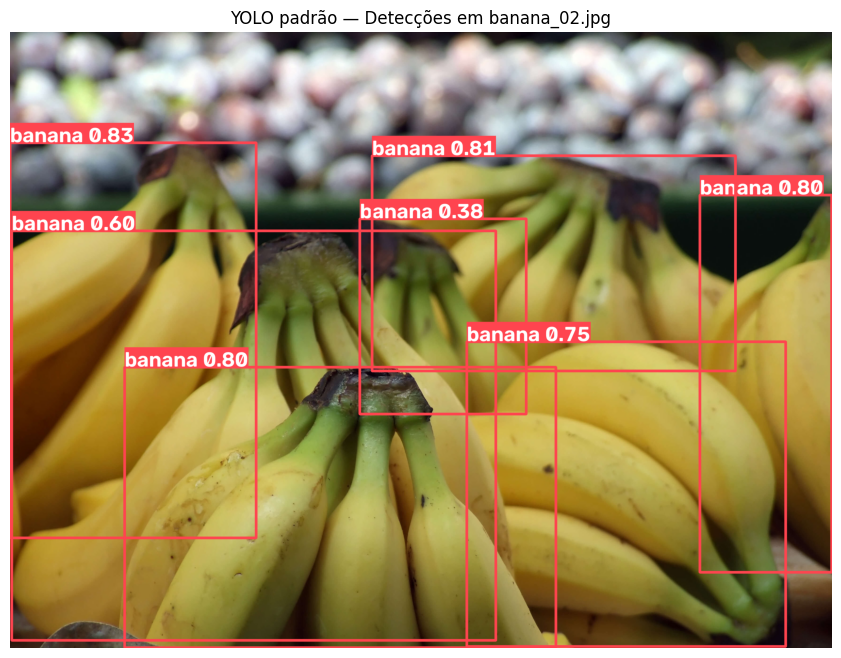

In [6]:
# Registro historico protegido; nenhuma execucao de modelo neste fluxo.
# Avaliacao independente: procedimentos da secao 8, em processo novo.
if False:
    import matplotlib.pyplot as plt

    imagem = DATASET / "test" / "images" / "banana" / "banana_02.jpg"

    resultado = modelo_padrao.predict(
        source=str(imagem),
        imgsz=640,
        conf=0.25,
        verbose=False
    )[0]

    plt.figure(figsize=(12, 8))
    plt.imshow(resultado.plot()[..., ::-1])
    plt.axis("off")
    plt.title("YOLO padrão — Detecções em banana_02.jpg")
    plt.show()
else:
    print("Registro historico preservado; use o procedimento independente da secao 8.")



### 3.3. Inspeção visual das detecções — banana_02.jpg

**Objetivo**

Examinar visualmente as caixas delimitadoras (*bounding boxes*) produzidas pela YOLOv5u, verificando a localização dos objetos e possíveis sobreposições entre as detecções.

**Procedimento**

Foi utilizada a função `plot()` da biblioteca Ultralytics para apresentar a imagem original com as caixas previstas, os nomes das classes e os respectivos níveis de confiança.

**Resultados observados**

A visualização apresentou sete detecções da classe banana, com diferentes níveis de confiança.

Observou-se a presença de caixas sobrepostas, indicando a possibilidade de múltiplas detecções associadas a uma mesma região da imagem.

**Interpretação crítica**

A inspeção visual é importante para identificar problemas que não são evidentes apenas pela quantidade de detecções ou pelos níveis de confiança.

Entretanto, a análise visual isolada não permite determinar com precisão quantas caixas correspondem aos objetos efetivamente anotados.

Para realizar essa verificação, as previsões serão comparadas às anotações originais do dataset, utilizando o índice de interseção sobre união (IoU).

Essa comparação permitirá identificar verdadeiros positivos, falsos positivos e falsos negativos, fornecendo uma avaliação quantitativa mais consistente.


In [7]:
# Registro historico protegido; nenhuma execucao de modelo neste fluxo.
# Avaliacao independente: procedimentos da secao 8, em processo novo.
if False:
    rotulo = DATASET / "test" / "labels" / "banana" / "banana_02.txt"

    with open(rotulo, encoding="utf-8") as arquivo:
        anotacoes = [linha.strip() for linha in arquivo if linha.strip()]

    print("Imagem: banana_02.jpg")
    print("Quantidade de objetos rotulados:", len(anotacoes))

    for numero, anotacao in enumerate(anotacoes, 1):
        print(f"Objeto {numero}: {anotacao}")
else:
    print("Registro historico preservado; use o procedimento independente da secao 8.")


Imagem: banana_02.jpg
Quantidade de objetos rotulados: 4
Objeto 1: 0 0.444771 0.785891 0.509592 0.428218
Objeto 2: 0 0.912438 0.503094 0.175124 0.530941
Objeto 3: 0 0.642481 0.356436 0.353651 0.289604
Objeto 4: 0 0.157952 0.356436 0.314666 0.378713



### 3.4. Conferência dos rótulos originais — banana_02.jpg

**Objetivo**

Verificar a quantidade de objetos anotados na imagem `banana_02.jpg`, estabelecendo a referência necessária para avaliar as detecções produzidas pela YOLOv5u.

**Metodologia**

O arquivo de anotação foi lido diretamente do conjunto de teste, preservando os registros produzidos durante a rotulação original.

As anotações seguem o formato YOLO, composto por cinco valores:

- Identificador da classe.
- Coordenada horizontal do centro da caixa (`x_center`).
- Coordenada vertical do centro da caixa (`y_center`).
- Largura da caixa (`width`).
- Altura da caixa (`height`).

As coordenadas são normalizadas em relação às dimensões da imagem, assumindo valores entre 0 e 1.

**Resultados**

O arquivo `banana_02.txt` contém quatro objetos anotados, todos associados à classe 0, correspondente à banana no dataset da FarmTech Neural Vision.

O modelo YOLOv5u havia produzido sete detecções para essa mesma imagem.

**Interpretação crítica**

A diferença entre quatro objetos anotados e sete detecções previstas indica a necessidade de investigar possíveis detecções redundantes ou incorretas.

Entretanto, a diferença numérica não permite determinar, isoladamente, quais previsões estão corretas.

A próxima etapa comparará as coordenadas das caixas previstas com as anotações originais, utilizando o índice IoU e correspondência individual entre detecções e objetos reais.


In [8]:
# Registro historico protegido; nenhuma execucao de modelo neste fluxo.
# Avaliacao independente: procedimentos da secao 8, em processo novo.
if False:
    import torch
    from ultralytics.utils.metrics import box_iou

    # Reutilizar o resultado da imagem banana_02
    resultado = modelo_padrao.predict(
        source=str(imagem),
        imgsz=640,
        conf=0.25,
        verbose=False
    )[0]

    altura, largura = resultado.orig_shape

    # Converter os rótulos YOLO para coordenadas de pixels
    caixas_reais = []

    for linha in anotacoes:
        classe, cx, cy, w, h = map(float, linha.split())

        if int(classe) == 0:  # banana no dataset original
            caixas_reais.append([
                (cx - w / 2) * largura,
                (cy - h / 2) * altura,
                (cx + w / 2) * largura,
                (cy + h / 2) * altura
            ])

    # Considerar somente as detecções de banana
    previsoes = resultado.boxes.xyxy[
        resultado.boxes.cls == 46
    ].cpu()

    reais = torch.tensor(caixas_reais, dtype=torch.float32)

    # Correspondência única entre previsão e rótulo (IoU >= 0.5)
    ious = box_iou(previsoes, reais)

    usados = set()
    tp = 0

    for linha in ious:
        for j in torch.argsort(linha, descending=True).tolist():
            if linha[j] >= 0.5 and j not in usados:
                usados.add(j)
                tp += 1
                break

    fp = len(previsoes) - tp
    fn = len(reais) - tp

    precision = tp / (tp + fp) if tp + fp else 0
    recall = tp / (tp + fn) if tp + fn else 0

    print("Objetos anotados:", len(reais))
    print("Detecções previstas:", len(previsoes))
    print("Verdadeiros positivos:", tp)
    print("Falsos positivos:", fp)
    print("Falsos negativos:", fn)
    print(f"Precision: {precision:.2%}")
    print(f"Recall: {recall:.2%}")
else:
    print("Registro historico preservado; use o procedimento independente da secao 8.")


Objetos anotados: 4
Detecções previstas: 7
Verdadeiros positivos: 4
Falsos positivos: 3
Falsos negativos: 0
Precision: 57.14%
Recall: 100.00%



### 3.5. Avaliação quantitativa da detecção — banana_02.jpg

**Objetivo**

Avaliar quantitativamente a capacidade da YOLOv5u pré-treinada de localizar os objetos anotados na imagem `banana_02.jpg`, utilizando Precision, Recall e o índice de interseção sobre união (IoU).

**Metodologia**

As coordenadas normalizadas das anotações originais foram convertidas para coordenadas em pixels, permitindo sua comparação com as caixas previstas pelo modelo.

Foi adotado IoU ≥ 0,50 como critério mínimo de correspondência espacial. Cada objeto anotado pôde ser associado a apenas uma previsão.

Foram contabilizados:

- **Verdadeiros positivos (TP):** detecções correspondentes aos objetos anotados.
- **Falsos positivos (FP):** detecções sem correspondência válida.
- **Falsos negativos (FN):** objetos anotados que não foram detectados.

**Resultados obtidos**

| Indicador | Resultado |
|---|---:|
| Objetos anotados | 4 |
| Detecções previstas | 7 |
| Verdadeiros positivos (TP) | 4 |
| Falsos positivos (FP) | 3 |
| Falsos negativos (FN) | 0 |
| Precision | 57,14% |
| Recall | 100,00% |

**Interpretação crítica**

O modelo localizou os quatro objetos anotados, alcançando Recall de 100% nesta imagem.

Entretanto, das sete detecções produzidas, apenas quatro apresentaram correspondência válida com objetos anotados, resultando em Precision de 57,14%.

Os três falsos positivos indicam detecções adicionais que não atenderam ao critério de correspondência adotado.

Esse comportamento demonstra que um modelo pode apresentar elevada capacidade de recuperação dos objetos e, simultaneamente, produzir previsões incorretas ou redundantes.

**Limitações**

Os resultados correspondem a uma única imagem e não representam o desempenho global do modelo.

Além disso, as métricas dependem do limiar de confiança, do critério IoU e da qualidade das anotações de referência.

A avaliação seguinte ampliará a análise para as oito imagens de teste.


In [9]:
# Registro historico protegido; nenhuma execucao de modelo neste fluxo.
# Avaliacao independente: procedimentos da secao 8, em processo novo.
if False:
    tp_total = fp_total = fn_total = 0

    for classe_real in ["banana", "milho"]:
        pasta = DATASET / "test" / "images" / classe_real

        for foto in sorted(pasta.glob("*.jpg")):
            resultado = modelo_padrao.predict(
                source=str(foto),
                imgsz=640,
                conf=0.25,
                verbose=False
            )[0]

            altura, largura = resultado.orig_shape
            rotulo = DATASET / "test" / "labels" / classe_real / f"{foto.stem}.txt"

            reais = []
            for linha in rotulo.read_text(encoding="utf-8").splitlines():
                classe, cx, cy, w, h = map(float, linha.split())

                if int(classe) == 0:
                    reais.append([
                        (cx-w/2)*largura, (cy-h/2)*altura,
                        (cx+w/2)*largura, (cy+h/2)*altura
                    ])

            id_banana = next(
                i for i, nome in resultado.names.items()
                if nome == "banana"
            )

            previsoes = resultado.boxes.xyxy[
                resultado.boxes.cls == id_banana
            ].cpu()

            confiancas = resultado.boxes.conf[
                resultado.boxes.cls == id_banana
            ].cpu()

            tp = 0
            usados = set()

            if len(previsoes) and len(reais):
                ious = box_iou(
                    previsoes,
                    torch.tensor(reais, dtype=torch.float32)
                )

                # Priorizar previsões com maior confiança
                for i in torch.argsort(confiancas, descending=True).tolist():
                    for j in torch.argsort(ious[i], descending=True).tolist():
                        if float(ious[i, j]) >= 0.5 and j not in usados:
                            usados.add(j)
                            tp += 1
                            break

            fp = len(previsoes) - tp
            fn = len(reais) - tp

            tp_total += tp
            fp_total += fp
            fn_total += fn

            print(f"{foto.name}: TP={tp}, FP={fp}, FN={fn}")

    precision = tp_total / (tp_total + fp_total) if tp_total + fp_total else 0
    recall = tp_total / (tp_total + fn_total) if tp_total + fn_total else 0

    print("\nRESULTADO GERAL — CLASSE BANANA")
    print(f"TP: {tp_total} | FP: {fp_total} | FN: {fn_total}")
    print(f"Precision: {precision:.2%}")
    print(f"Recall: {recall:.2%}")
else:
    print("Registro historico preservado; use o procedimento independente da secao 8.")


banana_01.jpg: TP=0, FP=0, FN=3
banana_02.jpg: TP=4, FP=3, FN=0
banana_03.jpg: TP=1, FP=0, FN=0
banana_04.jpg: TP=1, FP=0, FN=0
milho_01.jpg: TP=0, FP=0, FN=0
milho_02.jpg: TP=0, FP=0, FN=0
milho_03.jpg: TP=0, FP=0, FN=0
milho_04.jpg: TP=0, FP=0, FN=0

RESULTADO GERAL — CLASSE BANANA
TP: 6 | FP: 3 | FN: 3
Precision: 66.67%
Recall: 66.67%



### 3.6. Avaliação quantitativa da YOLOv5u — conjunto de teste

**Objetivo**

Avaliar a capacidade da YOLOv5u pré-treinada de detectar objetos da classe banana nas oito imagens de teste da FarmTech Neural Vision, utilizando as anotações originais como referência.

**Metodologia**

Foram processadas quatro imagens de banana e quatro imagens de milho, mantendo os seguintes parâmetros:

- Modelo: YOLOv5u pré-treinada (`yolov5su.pt`).
- Resolução de entrada: 640 pixels.
- Confiança mínima: 0,25.
- IoU mínimo para correspondência: 0,50.
- Correspondência individual entre detecção e objeto anotado, priorizando as previsões com maior confiança.

A avaliação considerou exclusivamente a classe banana. As imagens de milho foram incluídas para verificar possíveis detecções incorretas de banana.

Foram contabilizados os verdadeiros positivos (TP), falsos positivos (FP) e falsos negativos (FN).

**Resultados obtidos**

| Indicador | Resultado |
|---|---:|
| Objetos de banana anotados | 9 |
| Verdadeiros positivos (TP) | 6 |
| Falsos positivos (FP) | 3 |
| Falsos negativos (FN) | 3 |
| Precision | 66,67% |
| Recall | 66,67% |

**Análise por imagem**

- `banana_01.jpg`: três objetos não detectados.
- `banana_02.jpg`: quatro detecções corretas e três falsos positivos.
- `banana_03.jpg`: um objeto corretamente detectado.
- `banana_04.jpg`: um objeto corretamente detectado.
- Imagens de milho: nenhuma detecção incorreta da classe banana.

**Interpretação crítica**

A Precision de 66,67% indica que aproximadamente dois terços das detecções de banana foram consideradas corretas segundo os critérios adotados.

O Recall de 66,67% indica que o modelo recuperou seis dos nove objetos de banana anotados no conjunto de teste.

Os resultados demonstram capacidade de detecção sem treinamento específico com o dataset da FarmTech, mas também evidenciam objetos não identificados e detecções adicionais.

**Limitações da avaliação**

O conjunto de teste possui apenas oito imagens, o que limita a estabilidade e a generalização dos resultados.

As métricas apresentadas correspondem exclusivamente à classe banana, considerando um limiar fixo de confiança e IoU.

Este procedimento não calcula Average Precision (AP) nem mean Average Precision (mAP), que exigem uma avaliação mais abrangente das previsões em diferentes limiares de confiança.

Os resultados constituem uma análise exploratória complementar. A comparação principal da Entrega 2 utilizará a YOLOv5s original, a YOLOv5 customizada e a CNN treinada do zero.


In [10]:
# Registro historico protegido; nenhuma execucao de modelo neste fluxo.
# Avaliacao independente: procedimentos da secao 8, em processo novo.
if False:
    import torch

    modelo_yolov5s = torch.hub.load(
        "ultralytics/yolov5",
        "yolov5s",
        pretrained=True,
        trust_repo=True,
        device="cpu"
    )

    modelo_yolov5s.conf = 0.25

    print("YOLOv5s original carregada com sucesso.")
    print("Quantidade de classes:", len(modelo_yolov5s.names))
else:
    print("Registro historico preservado; use o procedimento independente da secao 8.")


Downloading: "https://github.com/ultralytics/yolov5/zipball/master" to C:\Users\Georgia/.cache\torch\hub\master.zip
requirements: Ultralytics requirement ['ultralytics>=8.4.192'] not found, attempting AutoUpdate...
   ---------------------------------------- 0.0/1.4 MB ? eta -:--:--
   --------------------- ------------------ 0.8/1.4 MB 5.5 MB/s eta 0:00:01
   ---------------------------------------- 1.4/1.4 MB 6.5 MB/s  0:00:00

  Attempting uninstall: ultralytics-thop

    Found existing installation: ultralytics-thop 2.2.2

    Uninstalling ultralytics-thop-2.2.2:

      Successfully uninstalled ultralytics-thop-2.2.2

  Attempting uninstall: ultralytics-platform

    Found existing installation: ultralytics-platform 0.1.80

    Uninstalling ultralytics-platform-0.1.80:

      Successfully uninstalled ultralytics-platform-0.1.80

   ------------- -------------------------- 1/3 [ultralytics-platform]
   ------------- -------------------------- 1/3 [ultralytics-platform]
   ----------

100%|██████████| 14.1M/14.1M [00:01<00:00, 10.5MB/s]

Fusing layers... 
YOLOv5s summary: 124 layers, 7,225,885 parameters, 0 gradients, 16.4 GFLOPs
Adding AutoShape... 
YOLOv5s original carregada com sucesso.
Quantidade de classes: 80



### 4. YOLOv5s original — Carregamento do modelo pré-treinado

**Objetivo**

Carregar a YOLOv5s com pesos pré-treinados, sem customização, para estabelecer uma referência de comparação com a YOLOv5s adaptada ao reconhecimento de banana e milho na Entrega 1.

**Metodologia**

O modelo foi carregado por meio do PyTorch Hub, utilizando o repositório oficial da YOLOv5 e os pesos `yolov5s.pt`.

A configuração utilizada foi:

- Arquitetura: YOLOv5s.
- Pesos: pré-treinados no conjunto COCO, sem treinamento adicional com as imagens de banana e milho utilizadas neste projeto.
- Classes originais: 80 categorias do conjunto COCO.
- Confiança mínima: 0,25.
- Ambiente da execução registrada: CPU.

**Resultados da execução**

O carregamento foi concluído com sucesso.

O modelo apresentou 124 camadas e aproximadamente 7,23 milhões de parâmetros, conforme o resumo produzido durante a execução.

Os pesos pré-treinados foram obtidos automaticamente. Também ocorreu uma atualização da biblioteca Ultralytics para atender às dependências do código carregado.

**Interpretação técnica**

A YOLOv5s pré-treinada constitui a referência para investigar o efeito da customização realizada na Entrega 1.

A comparação permitirá discutir as diferenças entre utilizar diretamente um modelo pré-treinado e adaptá-lo a objetos específicos de um determinado cenário.

**Reprodutibilidade**

A execução utilizou o código disponível na versão principal do repositório YOLOv5 na data do carregamento.

O commit completo dessa execução histórica não foi registrado. O procedimento independente exige um checkout local limpo e um SHA completo explícito, em vez de selecionar `master` ou `main`. Não foi escolhida uma revisão substituta para a YOLO padrão: sua compatibilidade e o eventual efeito nas predições dependem de validação separada.

O carregamento confirma a disponibilidade do modelo, mas não constitui, isoladamente, uma avaliação de desempenho.


In [11]:
# Registro historico protegido; nenhuma execucao de modelo neste fluxo.
# Avaliacao independente: procedimentos da secao 8, em processo novo.
if False:
    import time

    for classe in ["banana", "milho"]:
        pasta = DATASET / "test" / "images" / classe

        for foto in sorted(pasta.glob("*.jpg")):
            inicio = time.perf_counter()

            resultado = modelo_yolov5s(str(foto), size=640)

            tempo_ms = (time.perf_counter() - inicio) * 1000

            deteccoes = resultado.pandas().xyxy[0]

            print(f"\nImagem: {foto.name}")
            print(f"Tempo total: {tempo_ms:.1f} ms")

            if deteccoes.empty:
                print("Nenhum objeto detectado.")
            else:
                print(
                    deteccoes[["name", "confidence"]]
                    .to_string(index=False)
                )
else:
    print("Registro historico preservado; use o procedimento independente da secao 8.")



Imagem: banana_01.jpg
Tempo total: 352.5 ms
name  confidence
vase    0.619246

Imagem: banana_02.jpg
Tempo total: 452.4 ms
  name  confidence
banana    0.739338
banana    0.551891
banana    0.362792
banana    0.360863
banana    0.282543
banana    0.264639

Imagem: banana_03.jpg
Tempo total: 288.6 ms
  name  confidence
banana    0.563927

Imagem: banana_04.jpg
Tempo total: 212.6 ms
  name  confidence
banana    0.613927

Imagem: milho_01.jpg
Tempo total: 450.4 ms
Nenhum objeto detectado.

Imagem: milho_02.jpg
Tempo total: 427.2 ms
        name  confidence
dining table    0.376981

Imagem: milho_03.jpg
Tempo total: 376.0 ms
Nenhum objeto detectado.

Imagem: milho_04.jpg
Tempo total: 344.1 ms
   name  confidence
hot dog    0.472377



### 4.1. Avaliação preliminar da YOLOv5s original

**Objetivo**

Avaliar o comportamento da YOLOv5s pré-treinada nas oito imagens de teste, identificando os objetos detectados, os níveis de confiança e o tempo de processamento.

**Metodologia**

O modelo foi executado sem treinamento adicional, utilizando:

- Pesos: `yolov5s.pt`.
- Resolução de entrada: 640 pixels.
- Confiança mínima: 0,25.
- Conjunto de teste: quatro imagens de banana e quatro de milho.
- Ambiente da execução registrada: CPU.

O tempo foi medido utilizando `time.perf_counter()`, considerando a chamada completa de processamento de cada imagem.

**Resultados observados**

| Imagem | Detecções realizadas |
|---|---|
| banana_01.jpg | vase |
| banana_02.jpg | 6 detecções de banana |
| banana_03.jpg | banana |
| banana_04.jpg | banana |
| milho_01.jpg | Nenhuma |
| milho_02.jpg | dining table |
| milho_03.jpg | Nenhuma |
| milho_04.jpg | hot dog |

O modelo identificou pelo menos uma banana em três das quatro imagens dessa classe.

O tempo médio total de processamento foi de **362,98 ms por imagem**, considerando as oito execuções.

**Interpretação crítica**

A YOLOv5s original apresentou capacidade de identificar bananas sem treinamento adicional com as imagens do projeto.

Entretanto, também produziu classificações incompatíveis com os objetos esperados, como `vase` e `hot dog`.

A quantidade de detecções não determina, isoladamente, a qualidade da localização dos objetos. Para verificar as correspondências, é necessário comparar as caixas previstas com as anotações originais.

**Limitações**

O conjunto de teste é reduzido, restringindo a generalização dos resultados.

Os tempos foram obtidos em CPU e não devem ser comparados diretamente com medições realizadas em GPU.

Esta avaliação é preliminar. O cálculo de Precision e Recall, utilizando as anotações originais e o critério IoU, será realizado na etapa seguinte.

A comparação final também considerará a diferença entre a tarefa de detecção de objetos, realizada pelas redes YOLO, e a classificação de imagens, realizada pela CNN.


In [12]:
# Registro historico protegido; nenhuma execucao de modelo neste fluxo.
# Avaliacao independente: procedimentos da secao 8, em processo novo.
if False:

    import torch
    from torchvision.ops import box_iou

    id_banana = next(
        i for i in range(len(modelo_yolov5s.names))
        if modelo_yolov5s.names[i] == "banana"
    )

    tp_total = fp_total = fn_total = 0

    for cultura in ["banana", "milho"]:
        pasta = DATASET / "test" / "images" / cultura

        for foto in sorted(pasta.glob("*.jpg")):
            resultado = modelo_yolov5s(str(foto), size=640)
            predicoes = resultado.xyxy[0].detach().cpu()

            # Selecionar somente detecções da classe banana
            predicoes = predicoes[predicoes[:, 5] == id_banana]

            # Ler as anotações originais
            arquivo = DATASET / "test" / "labels" / cultura / f"{foto.stem}.txt"
            altura, largura = resultado.ims[0].shape[:2]
            caixas_reais = []

            for linha in arquivo.read_text(encoding="utf-8").splitlines():
                classe, cx, cy, w, h = map(float, linha.split())

                if int(classe) == 0:
                    caixas_reais.append([
                        (cx - w / 2) * largura,
                        (cy - h / 2) * altura,
                        (cx + w / 2) * largura,
                        (cy + h / 2) * altura
                    ])

            tp = 0
            usados = set()

            if len(predicoes) and caixas_reais:
                reais = torch.tensor(caixas_reais, dtype=torch.float32)
                ious = box_iou(predicoes[:, :4], reais)

                # Priorizar previsões com maior confiança
                ordem = torch.argsort(predicoes[:, 4], descending=True)

                for i in ordem.tolist():
                    for j in torch.argsort(ious[i], descending=True).tolist():
                        if float(ious[i, j]) >= 0.50 and j not in usados:
                            usados.add(j)
                            tp += 1
                            break

            fp = len(predicoes) - tp
            fn = len(caixas_reais) - tp

            tp_total += tp
            fp_total += fp
            fn_total += fn

            print(f"{foto.name}: TP={tp}, FP={fp}, FN={fn}")

    precision = tp_total / (tp_total + fp_total) if tp_total + fp_total else 0
    recall = tp_total / (tp_total + fn_total) if tp_total + fn_total else 0
    f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0

    print("\nRESULTADO — YOLOv5s ORIGINAL / CLASSE BANANA")
    print(f"TP: {tp_total} | FP: {fp_total} | FN: {fn_total}")
    print(f"Precision: {precision:.2%}")
    print(f"Recall: {recall:.2%}")
    print(f"F1-score: {f1:.2%}")
else:
    print("Registro historico preservado; use o procedimento independente da secao 8.")


banana_01.jpg: TP=0, FP=0, FN=3
banana_02.jpg: TP=4, FP=2, FN=0
banana_03.jpg: TP=1, FP=0, FN=0
banana_04.jpg: TP=1, FP=0, FN=0
milho_01.jpg: TP=0, FP=0, FN=0
milho_02.jpg: TP=0, FP=0, FN=0
milho_03.jpg: TP=0, FP=0, FN=0
milho_04.jpg: TP=0, FP=0, FN=0

RESULTADO — YOLOv5s ORIGINAL / CLASSE BANANA
TP: 6 | FP: 2 | FN: 3
Precision: 75.00%
Recall: 66.67%
F1-score: 70.59%



### 4.2. Avaliação quantitativa da YOLOv5s original

**Objetivo**

Avaliar quantitativamente a capacidade da YOLOv5s original, sem customização, de detectar objetos da classe banana, utilizando as anotações do conjunto de teste como referência.

**Metodologia**

Foram processadas oito imagens: quatro de banana e quatro de milho.

A avaliação utilizou os seguintes parâmetros:

- Modelo: YOLOv5s original (`yolov5s.pt`).
- Resolução de entrada: 640 pixels.
- Confiança mínima: 0,25.
- IoU mínimo para correspondência: 0,50.
- Correspondência individual entre previsões e objetos anotados, priorizando as detecções de maior confiança.

Foram contabilizados verdadeiros positivos (TP), falsos positivos (FP) e falsos negativos (FN), permitindo calcular Precision, Recall e F1-score.

**Resultados obtidos**

| Indicador | Resultado |
|---|---:|
| Objetos de banana anotados | 9 |
| Verdadeiros positivos (TP) | 6 |
| Falsos positivos (FP) | 2 |
| Falsos negativos (FN) | 3 |
| Precision | 75,00% |
| Recall | 66,67% |
| F1-score | 70,59% |

**Análise dos resultados**

A YOLOv5s original detectou corretamente seis dos nove objetos de banana anotados, alcançando Recall de 66,67%.

Entre as oito detecções previstas da classe banana, seis apresentaram correspondência válida com as anotações, resultando em Precision de 75,00%.

A imagem `banana_01.jpg` concentrou os três falsos negativos. Já a imagem `banana_02.jpg` apresentou quatro verdadeiros positivos e dois falsos positivos.

As demais imagens de banana tiveram seus objetos anotados detectados corretamente.

Nas quatro imagens de milho, não ocorreram detecções incorretas da classe banana.

**Interpretação crítica**

O modelo demonstrou capacidade de localizar parte dos objetos de interesse sem treinamento adicional com as imagens do projeto.

Entretanto, apresentou limitações de recuperação, deixando de identificar três objetos anotados, além de produzir duas detecções sem correspondência válida.

O F1-score de 70,59% representa o equilíbrio entre Precision e Recall nas condições específicas deste experimento.

**Limitações metodológicas**

Os resultados correspondem exclusivamente à avaliação da classe banana e não representam o desempenho do modelo na detecção das duas culturas.

As métricas foram calculadas com limiares fixos de confiança e IoU. Portanto, não equivalem ao cálculo de mAP utilizado na avaliação convencional de detectores de objetos.

O número reduzido de imagens limita a generalização das conclusões.

**Encaminhamento**

Os resultados serão incorporados à comparação entre a YOLOv5s original, a YOLOv5 customizada na Entrega 1 e a CNN treinada do zero, respeitando as diferenças entre detecção e classificação de imagens.



## 5. YOLOv5s customizada — Resultados da Entrega 1

### 5.1. Recuperação dos experimentos originais

**Objetivo**

Incorporar à comparação os resultados da YOLOv5s customizada para detectar banana e milho, desenvolvida na Entrega 1 da Fase 6.

**Origem dos resultados**

Os dados apresentados nesta seção foram extraídos das saídas executadas do notebook original `EdemirSufiatti_rm571375_pbl_fase6.ipynb`.

Os experimentos utilizaram a YOLOv5s com pesos iniciais pré-treinados e treinamento adicional sobre as imagens rotuladas do projeto.

Foram realizadas duas simulações, com 30 e 60 épocas, utilizando o mesmo dataset e configurações equivalentes, exceto pela quantidade de épocas.

**Resultados globais de validação**

| Métrica | 30 épocas | 60 épocas |
|---|---:|---:|
| Precision | 0,535 | 0,811 |
| Recall | 0,407 | 0,511 |
| mAP50 | 0,466 | 0,567 |
| mAP50-95 | 0,220 | 0,319 |
| Tempo total registrado | 796 s | 1.404 s |

Os resultados foram obtidos na validação dos melhores checkpoints (`best.pt`) de cada experimento, em ambiente Google Colab com GPU Tesla T4.

**Interpretação dos resultados**

Na execução registrada, o treinamento de 60 épocas apresentou resultados globais superiores nas quatro métricas de validação, embora tenha exigido maior tempo de processamento.

A melhora, entretanto, não ocorreu uniformemente entre as classes.

A classe milho apresentou evolução expressiva na simulação de 60 épocas, enquanto banana apresentou métricas inferiores às observadas na simulação de 30 épocas.

Isso demonstra a importância de analisar os resultados por classe, evitando conclusões fundamentadas exclusivamente nas métricas globais.

**Limitações metodológicas**

O conjunto de validação contém apenas oito imagens, o que limita a estabilidade das estimativas.

Os resultados de Precision, Recall e mAP apresentados nesta seção pertencem à avaliação de validação da Entrega 1 e foram preservados como evidências históricas.

Inicialmente, esses resultados não podiam ser diretamente comparados às métricas de teste da YOLOv5s padrão, devido à utilização de conjuntos de avaliação diferentes.

Entretanto, após a recuperação dos pesos originais, a YOLOv5s customizada de 60 épocas foi avaliada nas mesmas oito imagens de teste, permitindo complementar a comparação entre os modelos. Os resultados estão documentados na seção 7.3.

As métricas históricas de validação permanecem preservadas, sem serem apresentadas como resultados de um novo treinamento.

**Identificação e preservação do checkpoint**

O arquivo original `best.pt`, gerado no treinamento de 60 épocas, foi renomeado para `yolov5s_custom_exp60_best.pt` e armazenado em `entrega_2/modelos/`.

A renomeação teve finalidade exclusivamente organizacional, sem modificar os pesos ou a arquitetura do modelo. A integridade foi confirmada por comparação dos hashes SHA-256 com o arquivo original recuperado.

O checkpoint foi carregado utilizando a revisão `4add2aff` da YOLOv5, com um ajuste de compatibilidade entre Linux e Windows, sem necessidade de repetir o treinamento.

**Atualização — Recuperação dos pesos e avaliação complementar**

Posteriormente, foram recuperados os checkpoints originais (`best.pt`) dos treinamentos de 30 e 60 épocas, juntamente com os respectivos registros experimentais.

O modelo de 60 épocas foi carregado com sucesso e submetido a uma avaliação complementar nas oito imagens do conjunto de teste, utilizando confiança mínima de 0,25 e IoU ≥ 0,50.

Os resultados dessa avaliação estão documentados na seção 7.3, permitindo uma comparação mais consistente com a YOLOv5s padrão, avaliada no mesmo conjunto de teste.

Os resultados históricos de validação permanecem preservados nesta seção, sem alterações ou substituições por métricas de teste.


**Rastreabilidade das revisões — conferência de 03/11/2026**

O campo `git.commit` do checkpoint recuperado registra `f9578796b8a64889aa9e66dc06914d19f40d338e`. Esse metadado é distinto da revisão `4add2aff`, registrada nos logs do notebook original e comprovadamente usada no carregamento complementar em Python 3.13.13/CPU. A correspondência entre essas trilhas de revisão não foi estabelecida. O metadado interno não é atribuído de forma conclusiva à execução de treinamento documentada; a diferença também não demonstra alteração dos pesos. A integridade do artefato selecionado permanece identificada pelo SHA-256 registrado no CHANGELOG.


### 5.2. Comparação do desempenho por classe

**Objetivo**

Analisar separadamente o desempenho da YOLOv5s customizada nas classes banana e milho, comparando os experimentos de 30 e 60 épocas.

**Resultados de validação — Classe banana**

| Métrica | 30 épocas | 60 épocas |
|---|---:|---:|
| Precision | 0,763 | 0,652 |
| Recall | 0,385 | 0,308 |
| mAP50 | 0,489 | 0,377 |
| mAP50-95 | 0,178 | 0,160 |

**Resultados de validação — Classe milho**

| Métrica | 30 épocas | 60 épocas |
|---|---:|---:|
| Precision | 0,307 | 0,970 |
| Recall | 0,429 | 0,714 |
| mAP50 | 0,442 | 0,757 |
| mAP50-95 | 0,263 | 0,477 |

**Análise crítica**

Os resultados evidenciam comportamentos distintos entre as duas classes.

Na classe banana, todas as métricas apresentaram redução no experimento de 60 épocas. O Recall passou de 0,385 para 0,308, enquanto o mAP50 diminuiu de 0,489 para 0,377.

Esse resultado indica que o aumento do número de épocas não produziu melhora de desempenho para essa classe na execução registrada.

Na classe milho, ocorreu o comportamento oposto. A Precision aumentou de 0,307 para 0,970, o Recall passou de 0,429 para 0,714 e o mAP50 aumentou de 0,442 para 0,757.

Assim, a melhora global observada no treinamento de 60 épocas foi acompanhada de uma melhora expressiva no reconhecimento de milho, mas não de banana.

**Possíveis fatores associados**

O notebook original registra diferenças no processo de curadoria das imagens e na quantidade de instâncias rotuladas para cada classe.

O milho passou por uma seleção manual mais criteriosa, enquanto as imagens de banana apresentaram maior heterogeneidade e inconsistências identificadas nas anotações.

Essas características podem estar associadas às diferenças de desempenho, mas os experimentos realizados não permitem estabelecer relações de causa e efeito.

**Limitações**

Os resultados foram calculados em apenas oito imagens de validação, contendo 13 instâncias anotadas de banana e sete de milho.

A quantidade reduzida de instâncias torna as métricas sensíveis a pequenas alterações nas detecções.

Portanto, não é possível concluir que 60 épocas sejam universalmente superiores a 30 épocas ou que a rede apresente a mesma capacidade de generalização em novos cenários.

**Conclusão parcial**

A análise por classe demonstra que uma melhora nas métricas globais não implica melhora uniforme de todas as categorias reconhecidas.

A seleção de um modelo deve considerar tanto o desempenho agregado quanto as necessidades específicas da aplicação e os resultados individuais de cada classe.



## 6. CNN treinada do zero — Classificação de banana e milho

### 6.1. Objetivo e metodologia

**Objetivo**

Avaliar uma rede neural convolucional (CNN) treinada do zero para classificar imagens das culturas banana e milho, utilizando o mesmo conjunto de dados da Entrega 1.

**Metodologia**

A implementação utiliza uma arquitetura CNN com pesos inicialmente aleatórios, sem recorrer a modelos pré-treinados.

O experimento considera:

- 64 imagens de treinamento;
- 8 imagens de validação;
- 8 imagens de teste;
- duas classes: banana e milho;
- imagens redimensionadas para 224 × 224 pixels.

A arquitetura utiliza blocos convolucionais, operações de max pooling e uma camada final de classificação binária.

**Origem da implementação**


**Implementação da CNN**

A CNN foi implementada neste notebook como terceira abordagem experimental da Entrega 2, utilizando o dataset de banana e milho preparado na Entrega 1.

A arquitetura, o treinamento e a avaliação históricos são apresentados nas seções seguintes. Para avaliar o modelo preservado em uma sessão nova, sem treinamento, utilize `avaliar_cnn.py`, conforme a seção 8. A nova implementação de avaliação ainda depende de validação funcional.

O experimento utiliza uma arquitetura convolucional construída do zero, sem transferência de pesos pré-treinados.


In [1]:
# Registro historico protegido; nenhuma execucao de modelo neste fluxo.
# Avaliacao independente: procedimentos da secao 8, em processo novo.
if False:
    import sys

    print("Python:", sys.version.split()[0])

    try:
        import tensorflow as tf
        print("TensorFlow:", tf.__version__)
        print("GPU disponível:", bool(tf.config.list_physical_devices("GPU")))
    except Exception as erro:
        print("TensorFlow indisponível neste ambiente.")
        print("Motivo:", str(erro))
else:
    print("Registro historico preservado; use o procedimento independente da secao 8.")


Python: 3.13.13
TensorFlow: 2.21.0
GPU disponível: False


In [3]:
import importlib.util

for biblioteca in ["tensorflow", "numpy", "cv2", "torch", "torchvision", "ultralytics"]:
    disponivel = importlib.util.find_spec(biblioteca) is not None
    print(f"{biblioteca}: {'OK' if disponivel else 'NÃO INSTALADA'}")

tensorflow: OK
numpy: OK
cv2: OK
torch: OK
torchvision: OK
ultralytics: OK


In [5]:
# Registro historico protegido; nenhuma execucao de modelo neste fluxo.
# Avaliacao independente: procedimentos da secao 8, em processo novo.
if False:

    import numpy as np
    import cv2

    # Configurações utilizadas na CNN original
    CLASSES = ["banana", "milho"]
    TAMANHO = 224

    def carregar_imagens(pasta_base, conjunto):
        imagens, rotulos, caminhos = [], [], []

        for indice, classe in enumerate(CLASSES):
            pasta = pasta_base / conjunto / "images" / classe

            for foto in sorted(pasta.glob("*.jpg")):
                imagem = cv2.imread(str(foto))

                if imagem is None:
                    raise ValueError(f"Falha ao carregar: {foto}")

                imagem = cv2.cvtColor(imagem, cv2.COLOR_BGR2RGB)
                imagem = cv2.resize(
                    imagem,
                    (TAMANHO, TAMANHO),
                    interpolation=cv2.INTER_AREA
                )

                imagens.append(imagem)
                rotulos.append(indice)
                caminhos.append(foto)

        return (
            np.array(imagens, dtype=np.float32),
            np.array(rotulos, dtype=np.float32),
            caminhos
        )


    # Carregamento dos três conjuntos independentes
    x_treino, y_treino, caminhos_treino = carregar_imagens(DATASET, "train")
    x_val, y_val, caminhos_val = carregar_imagens(DATASET, "val")
    x_teste, y_teste, caminhos_teste = carregar_imagens(DATASET, "test")

    print("Treinamento:", x_treino.shape)
    print("Validação:", x_val.shape)
    print("Teste:", x_teste.shape)

    print("\nDistribuição das classes:")
    for nome, rotulos in [
        ("Treinamento", y_treino),
        ("Validação", y_val),
        ("Teste", y_teste)
    ]:
        print(
            f"{nome}: "
            f"banana={int((rotulos == 0).sum())}, "
            f"milho={int((rotulos == 1).sum())}"
        )
else:
    print("Registro historico preservado; use o procedimento independente da secao 8.")


Treinamento: (64, 224, 224, 3)
Validação: (8, 224, 224, 3)
Teste: (8, 224, 224, 3)

Distribuição das classes:
Treinamento: banana=32, milho=32
Validação: banana=4, milho=4
Teste: banana=4, milho=4



### 6.2. Preparação dos dados para classificação

**Objetivo**

Preparar as imagens de banana e milho para o treinamento, a validação e o teste da CNN, preservando a divisão original do dataset da FarmTech Neural Vision.

**Metodologia**


O carregamento foi realizado com OpenCV e NumPy, utilizando o dataset da Entrega 1. O procedimento preserva a divisão original entre treinamento, validação e teste e prepara as imagens para a classificação supervisionada pela CNN.


As imagens foram submetidas às seguintes operações:

1. Leitura dos arquivos no formato JPG.
2. Conversão do padrão de cores BGR para RGB.
3. Redimensionamento para 224 × 224 pixels.
4. Conversão para arrays NumPy do tipo `float32`.
5. Associação dos rótulos: banana = 0 e milho = 1.

As classes foram determinadas pelos diretórios das imagens. Diferentemente da detecção de objetos, a classificação utiliza um rótulo por imagem, sem considerar diretamente as coordenadas das caixas delimitadoras.

**Resultados da execução**

| Conjunto | Banana | Milho | Total |
|---|---:|---:|---:|
| Treinamento | 32 | 32 | 64 |
| Validação | 4 | 4 | 8 |
| Teste | 4 | 4 | 8 |
| **Total** | **40** | **40** | **80** |

Todas as imagens foram carregadas com dimensões `(224, 224, 3)`, correspondentes à altura, largura e aos três canais de cores.

**Análise técnica**

A distribuição equilibrada evita que uma das classes tenha maior representatividade numérica nos conjuntos utilizados.

A separação entre treinamento, validação e teste permite utilizar as imagens de validação para acompanhar o aprendizado e reservar as imagens de teste para a avaliação final.

Nesta etapa, os pixels ainda permanecem na escala original de 0 a 255. A normalização será realizada internamente pela arquitetura da CNN.

**Limitações**

O conjunto contém apenas 64 imagens de treinamento e oito de teste. Esse tamanho reduzido pode afetar a capacidade de generalização e tornar as métricas sensíveis a poucos erros de classificação.

O carregamento bem-sucedido não comprova, isoladamente, a qualidade visual dos dados ou a ausência de imagens duplicadas.

**Conclusão parcial**

Os dados estão estruturados e disponíveis para a construção e o treinamento da CNN, preservando a organização e as classes do experimento original.


In [6]:
# Registro historico protegido; nenhuma execucao de modelo neste fluxo.
# Avaliacao independente: procedimentos da secao 8, em processo novo.
if False:

    import tensorflow as tf
    from tensorflow.keras import layers, models

    # Semente para favorecer a reprodutibilidade
    tf.keras.utils.set_random_seed(42)

    def camadas_aumento():
        """Aumento de dados aplicado somente durante o treinamento."""
        return tf.keras.Sequential([
            layers.RandomFlip("horizontal"),
            layers.RandomRotation(0.1),
            layers.RandomZoom(0.1),
        ], name="aumento")


    def cnn_do_zero():
        """CNN original, inicializada sem pesos pré-treinados."""
        return models.Sequential([
            layers.Input(shape=(TAMANHO, TAMANHO, 3)),

            # Aumento de dados e normalização
            camadas_aumento(),
            layers.Rescaling(1 / 255),

            # Extração progressiva de características
            layers.Conv2D(16, 3, activation="relu"),
            layers.MaxPooling2D(),

            layers.Conv2D(32, 3, activation="relu"),
            layers.MaxPooling2D(),

            layers.Conv2D(64, 3, activation="relu"),
            layers.MaxPooling2D(),

            # Classificação
            layers.GlobalAveragePooling2D(),
            layers.Dense(64, activation="relu"),
            layers.Dropout(0.3),
            layers.Dense(1, activation="sigmoid"),
        ], name="cnn_do_zero")


    # Construir a arquitetura
    modelo_cnn = cnn_do_zero()

    print("Arquitetura da CNN:")
    modelo_cnn.summary()

    print("\nTotal de parâmetros:", modelo_cnn.count_params())
else:
    print("Registro historico preservado; use o procedimento independente da secao 8.")


Arquitetura da CNN:


Model: "cnn_do_zero"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ aumento (Sequential)            │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 222, 222, 16)   │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 111, 111, 16)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 109, 109, 32)   │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 54, 54, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 52, 52, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 26, 26, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 64)             │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 27,809 (108.63 KB)

 Trainable params: 27,809 (108.63 KB)

 Non-trainable params: 0 (0.00 B)


Total de parâmetros: 27809



### 6.3. Arquitetura da CNN treinada do zero

**Objetivo**

Implementar uma rede neural convolucional para classificação binária de imagens de banana e milho, utilizando exclusivamente os dados de treinamento da FarmTech Neural Vision.

**Arquitetura implementada**

A CNN foi construída com TensorFlow/Keras e utiliza entrada de 224 × 224 pixels, com três canais de cores.

Sua estrutura compreende:

- Aumento de dados: espelhamento horizontal, rotação e zoom aleatórios durante o treinamento.
- Normalização: divisão dos valores dos pixels por 255.
- Primeiro bloco: convolução com 16 filtros, seguida de MaxPooling.
- Segundo bloco: convolução com 32 filtros, seguida de MaxPooling.
- Terceiro bloco: convolução com 64 filtros, seguida de MaxPooling.
- GlobalAveragePooling2D: redução dos mapas de características.
- Camada Dense: 64 neurônios com ativação ReLU.
- Dropout: taxa de 30% para regularização.
- Camada de saída: um neurônio com ativação sigmoid.

O valor da saída representa a probabilidade estimada da classe milho. O limiar de classificação será estabelecido em 0,5.

**Resultados da construção**

| Indicador | Resultado |
|---|---:|
| Parâmetros totais | 27.809 |
| Parâmetros treináveis | 27.809 |
| Parâmetros não treináveis | 0 |

Todos os parâmetros aprendíveis serão ajustados durante o treinamento, sem transferência de pesos de modelos previamente treinados.

**Justificativa técnica**

A arquitetura utiliza uma quantidade relativamente reduzida de parâmetros, considerando o tamanho limitado do conjunto de treinamento.

As camadas convolucionais extraem características visuais progressivamente, enquanto as operações de pooling reduzem as dimensões espaciais dos mapas.

A camada GlobalAveragePooling2D diminui a quantidade de parâmetros em comparação com uma abordagem baseada no achatamento completo dos mapas de características.

O aumento de dados e o Dropout são estratégias destinadas a reduzir o risco de overfitting, mas sua presença não garante capacidade de generalização.

**Limitações**

A construção bem-sucedida da arquitetura confirma sua integridade estrutural, mas ainda não demonstra capacidade de classificação.

A efetividade do modelo deverá ser examinada após treinamento, validação e avaliação no conjunto de teste.

**Conclusão parcial**


A CNN foi construída e validada estruturalmente, apresentando 27.809 parâmetros treináveis. A arquitetura está preparada para o treinamento supervisionado das classes banana e milho, conforme os objetivos da Entrega 2.



In [9]:
# Registro historico protegido; nenhuma execucao de modelo neste fluxo.
# Avaliacao independente: procedimentos da secao 8, em processo novo.
if False:

    import time
    import numpy as np

    # Configurações do experimento original
    EPOCAS = 60
    BATCH_SIZE = 8
    TAXA_APRENDIZADO = 0.001
    PACIENCIA = 8

    # Compilação do modelo
    modelo_cnn.compile(
        optimizer=tf.keras.optimizers.Adam(
            learning_rate=TAXA_APRENDIZADO
        ),
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )

    # Interromper treinamento quando a validação deixar de melhorar
    parada_antecipada = tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=PACIENCIA,
        restore_best_weights=True
    )

    # Treinamento
    inicio = time.perf_counter()

    historico_cnn = modelo_cnn.fit(
        x_treino,
        y_treino,
        validation_data=(x_val, y_val),
        epochs=EPOCAS,
        batch_size=BATCH_SIZE,
        shuffle=True,
        callbacks=[parada_antecipada],
        verbose=1
    )

    tempo_treino_cnn = time.perf_counter() - inicio

    # Identificação da melhor época
    melhor_epoca = int(
        np.argmin(historico_cnn.history["val_loss"])
    )

    print("\nRESULTADOS DO TREINAMENTO")
    print("Épocas executadas:", len(historico_cnn.history["loss"]))
    print("Melhor época:", melhor_epoca + 1)
    print(
        "Acurácia de validação na melhor época:",
        f'{historico_cnn.history["val_accuracy"][melhor_epoca]:.2%}'
    )
    print("Tempo de treinamento:", f"{tempo_treino_cnn:.2f} segundos")
else:
    print("Registro historico preservado; use o procedimento independente da secao 8.")


Epoch 1/60
8/8 ━━━━━━━━━━━━━━━━━━━━ 3s 115ms/step - accuracy: 0.4531 - loss: 0.6902 - val_accuracy: 0.5000 - val_loss: 0.6777
Epoch 2/60
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 87ms/step - accuracy: 0.5312 - loss: 0.6813 - val_accuracy: 0.5000 - val_loss: 0.6705
Epoch 3/60
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 97ms/step - accuracy: 0.5625 - loss: 0.6766 - val_accuracy: 0.5000 - val_loss: 0.6692
Epoch 4/60
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 91ms/step - accuracy: 0.5938 - loss: 0.6475 - val_accuracy: 0.5000 - val_loss: 0.6712
Epoch 5/60
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 86ms/step - accuracy: 0.6719 - loss: 0.6314 - val_accuracy: 0.5000 - val_loss: 0.6743
Epoch 6/60
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 87ms/step - accuracy: 0.7500 - loss: 0.6105 - val_accuracy: 0.5000 - val_loss: 0.6512
Epoch 7/60
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 99ms/step - accuracy: 0.7344 - loss: 0.5810 - val_accuracy: 0.5000 - val_loss: 0.6176
Epoch 8/60
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 90ms/step - accuracy: 0.7656 - loss: 0.5642 - val_accuracy: 0.5000 - val_loss: 0.5789


### 6.4. Treinamento supervisionado da CNN

**Objetivo**

Treinar a CNN para distinguir imagens de banana e milho, utilizando os conjuntos de treinamento e validação previamente preparados.

**Configuração experimental**

| Hiperparâmetro | Configuração |
|---|---|
| Otimizador | Adam |
| Taxa de aprendizado | 0,001 |
| Função de perda | Binary Crossentropy |
| Tamanho do lote (batch size) | 8 |
| Limite de épocas | 60 |
| Early Stopping | Monitoramento de `val_loss` |
| Paciência | 8 épocas |
| Restauração dos melhores pesos | Habilitada |
| Ambiente de execução | Python 3.13.13 / TensorFlow 2.21.0 / CPU |


Os hiperparâmetros foram definidos para o treinamento da CNN da Entrega 2, considerando o tamanho do dataset, a classificação binária e a utilização de Early Stopping para monitorar a perda de validação.


O treinamento utilizou 64 imagens, enquanto oito imagens foram reservadas para validação.

**Resultados obtidos**

| Indicador | Resultado |
|---|---:|
| Épocas executadas | 33 |
| Melhor época | 25 |
| Acurácia de validação na melhor época | 100,00% |
| Perda de validação na melhor época | 0,1878 |
| Tempo total de treinamento | 29,18 segundos |

**Análise dos resultados**

A perda de validação apresentou redução durante o treinamento, atingindo seu menor valor na época 25.

Após oito épocas consecutivas sem melhora desse indicador, o Early Stopping interrompeu o processo na época 33.

Como a restauração dos melhores pesos estava habilitada, o modelo retornou aos parâmetros correspondentes à época 25.

Na melhor época, a acurácia de validação foi de 100%, equivalente à classificação correta das oito imagens de validação.

**Interpretação crítica**

O resultado evidencia que a arquitetura conseguiu aprender características úteis para distinguir banana e milho no conjunto de validação utilizado.

Entretanto, a quantidade reduzida de imagens limita a confiabilidade estatística dessa avaliação. Cada erro corresponde a uma variação de 12,5 pontos percentuais na acurácia.

A utilização de Early Stopping contribui para controlar o treinamento com base na perda de validação, mas não garante ausência de overfitting.

Também não é possível atribuir causalmente o desempenho observado a um único componente da arquitetura ou estratégia de treinamento.


**Ambiente e condições de execução**

O treinamento foi realizado localmente, em ambiente Windows, utilizando Python 3.13.13, TensorFlow 2.21.0 e processamento em CPU.

O tempo total registrado foi de 29,18 segundos, considerando as 33 épocas executadas até a interrupção antecipada.

Esse tempo caracteriza as condições computacionais do experimento. Sua comparação com tempos de outros modelos exige considerar diferenças de hardware, bibliotecas e procedimentos de medição.

**Conclusão parcial**

A CNN foi treinada com sucesso, com interrupção antecipada e restauração dos melhores pesos.

A avaliação de generalização será realizada na próxima etapa, utilizando exclusivamente as oito imagens reservadas para teste.


In [19]:
# Registro historico protegido; nenhuma execucao de modelo neste fluxo.
# Avaliacao independente: procedimentos da secao 8, em processo novo.
if False:

    import time
    import numpy as np

    # Aquecimento do modelo antes da medição de tempo
    modelo_cnn.predict(x_teste[:1], verbose=0)

    # Inferência nas oito imagens de teste
    inicio = time.perf_counter()

    probabilidades = modelo_cnn.predict(
        x_teste,
        verbose=0
    ).ravel()

    tempo_inferencia = time.perf_counter() - inicio
    tempo_medio_ms = (tempo_inferencia / len(x_teste)) * 1000

    # Classificação binária: banana = 0, milho = 1
    previsoes = (probabilidades >= 0.5).astype(int)
    reais = y_teste.astype(int)

    # Acurácia
    acertos = int(np.sum(previsoes == reais))
    total = len(reais)
    acuracia_cnn = acertos / total

    print("RESULTADOS INDIVIDUAIS — CNN")
    print("-" * 65)

    for caminho, real, previsto, prob in zip(
        caminhos_teste, reais, previsoes, probabilidades
    ):
        situacao = "CORRETO" if real == previsto else "ERRO"

        print(
            f"{caminho.name}: "
            f"Real={CLASSES[real]} | "
            f"Previsto={CLASSES[previsto]} | "
            f"P(milho)={prob:.4f} | {situacao}"
        )

    # Matriz de confusão: linhas = real, colunas = previsto
    matriz = np.zeros((2, 2), dtype=int)

    for real, previsto in zip(reais, previsoes):
        matriz[real, previsto] += 1

    print("\nMATRIZ DE CONFUSÃO")
    print("                 Prev. banana   Prev. milho")
    print(f"Real banana      {matriz[0, 0]:12d} {matriz[0, 1]:13d}")
    print(f"Real milho       {matriz[1, 0]:12d} {matriz[1, 1]:13d}")

    print("\nMÉTRICAS POR CLASSE")

    for indice, classe in enumerate(CLASSES):
        tp = matriz[indice, indice]
        fp = matriz[:, indice].sum() - tp
        fn = matriz[indice, :].sum() - tp

        precision = tp / (tp + fp) if tp + fp else 0
        recall = tp / (tp + fn) if tp + fn else 0
        f1 = (
            2 * precision * recall / (precision + recall)
            if precision + recall else 0
        )

        print(
            f"{classe}: Precision={precision:.2%} | "
            f"Recall={recall:.2%} | F1={f1:.2%}"
        )

    print("\nRESUMO FINAL — CNN DO ZERO")
    print(f"Acertos: {acertos}/{total}")
    print(f"Acurácia no teste: {acuracia_cnn:.2%}")
    print(f"Tempo total de inferência: {tempo_inferencia:.4f} s")
    print(f"Tempo médio por imagem: {tempo_medio_ms:.2f} ms")
    print(f"Tempo de treinamento: {tempo_treino_cnn:.2f} s")
else:
    print("Registro historico preservado; use o procedimento independente da secao 8.")


RESULTADOS INDIVIDUAIS — CNN
-----------------------------------------------------------------
banana_01.jpg: Real=banana | Previsto=milho | P(milho)=0.8564 | ERRO
banana_02.jpg: Real=banana | Previsto=milho | P(milho)=0.7950 | ERRO
banana_03.jpg: Real=banana | Previsto=banana | P(milho)=0.0353 | CORRETO
banana_04.jpg: Real=banana | Previsto=banana | P(milho)=0.0517 | CORRETO
milho_01.jpg: Real=milho | Previsto=milho | P(milho)=0.8751 | CORRETO
milho_02.jpg: Real=milho | Previsto=milho | P(milho)=0.8620 | CORRETO
milho_03.jpg: Real=milho | Previsto=milho | P(milho)=0.8952 | CORRETO
milho_04.jpg: Real=milho | Previsto=milho | P(milho)=0.9508 | CORRETO

MATRIZ DE CONFUSÃO
                 Prev. banana   Prev. milho
Real banana                 2             2
Real milho                  0             4

MÉTRICAS POR CLASSE
banana: Precision=100.00% | Recall=50.00% | F1=66.67%
milho: Precision=66.67% | Recall=100.00% | F1=80.00%

RESUMO FINAL — CNN DO ZERO
Acertos: 6/8
Acurácia no teste: 7


### 6.5. Avaliação da CNN no conjunto de teste

**Objetivo**

Avaliar a capacidade de classificação da CNN treinada do zero utilizando oito imagens reservadas exclusivamente para teste: quatro de banana e quatro de milho.

**Metodologia**

A avaliação foi realizada com os pesos restaurados da melhor época de treinamento, selecionada pelo menor valor de perda de validação.

Para cada imagem, foram registrados:

- Classe verdadeira;
- Classe prevista;
- Probabilidade estimada da classe milho;
- Correção ou erro da classificação.

Foi utilizado limiar de 0,5 para a classificação binária:

- Valores inferiores a 0,5: banana;
- Valores iguais ou superiores a 0,5: milho.

Foram calculadas acurácia global, Precision, Recall e F1-score por classe, além da matriz de confusão e do tempo médio de inferência.

**Resultados gerais**

| Indicador | Resultado |
|---|---:|
| Imagens avaliadas | 8 |
| Classificações corretas | 6 |
| Classificações incorretas | 2 |
| Acurácia | 75,00% |
| Tempo total de inferência | 0,1471 s |
| Tempo médio de inferência | 18,39 ms/imagem |
| Tempo de treinamento | 29,18 s |

**Matriz de confusão**

| Classe real | Prevista: banana | Prevista: milho |
|---|---:|---:|
| Banana | 2 | 2 |
| Milho | 0 | 4 |

**Métricas por classe**

| Classe | Precision | Recall | F1-score |
|---|---:|---:|---:|
| Banana | 100,00% | 50,00% | 66,67% |
| Milho | 66,67% | 100,00% | 80,00% |

**Análise dos resultados**

A CNN classificou corretamente seis das oito imagens avaliadas, alcançando acurácia global de 75%.

Na classe banana, duas das quatro imagens foram classificadas corretamente. As imagens `banana_01.jpg` e `banana_02.jpg` foram incorretamente classificadas como milho, com probabilidades estimadas para essa classe de 0,8564 e 0,7950, respectivamente.

A Precision de banana atingiu 100%, pois todas as previsões realizadas como banana estavam corretas. Entretanto, o Recall de 50% demonstra que o modelo deixou de reconhecer metade das imagens pertencentes a essa classe.

Na classe milho, todas as quatro imagens foram classificadas corretamente, resultando em Recall de 100%.

A Precision de milho foi de 66,67%, pois, além das quatro previsões corretas, duas imagens de banana também receberam essa classificação.

Esses resultados demonstram que a acurácia global não descreve integralmente o comportamento do classificador.


**Limitações metodológicas**

O conjunto de teste contém apenas oito imagens, sendo quatro por classe. Dessa forma, cada erro individual corresponde a 12,5 pontos percentuais da acurácia global.

As probabilidades produzidas pela camada sigmoid representam as saídas estimadas do modelo, mas não foram submetidas a uma avaliação específica de calibração.

O tempo médio de inferência foi calculado pelo processamento das oito imagens em lote, após uma execução de aquecimento. Portanto, não representa necessariamente a latência de uma imagem processada individualmente.

A CNN executa classificação de imagens completas. Os modelos YOLO realizam detecção e localização de objetos. Consequentemente, suas métricas não devem ser comparadas diretamente como se representassem a mesma tarefa.

Os resultados observados não permitem estabelecer relações causais entre características isoladas do dataset, decisões arquiteturais e erros de classificação.

**Conclusão parcial**

A CNN treinada do zero demonstrou capacidade de distinguir banana e milho, alcançando 75% de acurácia no conjunto de teste.

Entretanto, apresentou maior dificuldade na recuperação das imagens de banana, apesar do desempenho integral na classe milho.

Esses resultados serão incorporados à avaliação crítica das três abordagens exigidas na Entrega 2, considerando suas diferenças metodológicas, precisão, custo computacional e facilidade de integração.


In [11]:
# Registro historico protegido; nenhuma execucao de modelo neste fluxo.
# Avaliacao independente: procedimentos da secao 8, em processo novo.
if False:

    pasta_modelos = DATASET.parent / "entrega_2" / "modelos"
    pasta_modelos.mkdir(parents=True, exist_ok=True)

    arquivo_modelo = pasta_modelos / "cnn_do_zero_fase6.keras"

    modelo_cnn.save(arquivo_modelo)

    print("Modelo salvo em:", arquivo_modelo)
    print("Arquivo existente:", arquivo_modelo.is_file())
else:
    print("Registro historico preservado; use o procedimento independente da secao 8.")


Modelo salvo em: c:\Users\Georgia\Desktop\farmtech-integracao\servicos\fase6-visao\entrega_2\modelos\cnn_do_zero_fase6.keras
Arquivo existente: True



## 7. Comparação crítica das três abordagens


### 7.1. Resultados experimentais e condições de avaliação

**Objetivo**

Consolidar as evidências experimentais das três abordagens exigidas na Entrega 2, identificando diferenças de desempenho, tempo de processamento e condições de avaliação.

**Resultados quantitativos no conjunto de teste**

| Abordagem | Classe | Precision | Recall | F1-score |
|---|---|---:|---:|---:|
| YOLOv5s padrão | Banana | 75,00% | 66,67% | 70,59% |
| YOLOv5s customizada — 60 épocas | Banana | 66,67% | 22,22% | 33,33% |
| YOLOv5s customizada — 60 épocas | Milho | 50,00% | 57,14% | 53,33% |
| CNN do zero | Banana | 100,00% | 50,00% | 66,67% |
| CNN do zero | Milho | 66,67% | 100,00% | 80,00% |

A CNN também apresentou acurácia global de 75%, classificando corretamente seis das oito imagens de teste.

A YOLOv5s padrão foi avaliada quantitativamente somente para banana, pois seus pesos pré-treinados não incluem uma classe específica para milho.

**Resultados históricos da YOLO customizada — validação**

| Indicador | 30 épocas | 60 épocas |
|---|---:|---:|
| Precision global | 53,50% | 81,10% |
| Recall global | 40,70% | 51,10% |
| mAP50 | 46,60% | 56,70% |
| mAP50-95 | 22,00% | 31,90% |

Esses resultados pertencem ao conjunto de validação da Entrega 1 e são apresentados separadamente dos resultados de teste.

**Tempos registrados**

| Abordagem | Treinamento | Tempo médio por imagem |
|---|---|---:|
| YOLOv5s padrão | Não realizado; pesos pré-treinados | 362,98 ms |
| YOLOv5s customizada — 60 épocas | 1.404 s | 322,42 ms |
| CNN treinada do zero | 29,18 s | 18,39 ms |

O experimento original da YOLO customizada de 30 épocas registrou 796 segundos de treinamento.

**Condições experimentais**

A YOLO customizada foi treinada originalmente no Google Colab com GPU Tesla T4. Sua avaliação de teste foi realizada localmente em CPU, utilizando os pesos originais recuperados.

A YOLO padrão e a CNN também foram avaliadas localmente em CPU.

Entretanto, os tempos de inferência não representam um benchmark rigorosamente equivalente:

- As duas YOLOs foram avaliadas por chamadas individuais às imagens.
- A CNN processou as oito imagens em lote, após aquecimento.
- Os tempos de treinamento pertencem a arquiteturas e ambientes computacionais diferentes.

**Limitações de comparabilidade**

As YOLOs realizam detecção de objetos, enquanto a CNN realiza classificação da imagem completa. Portanto, suas métricas não representam exatamente a mesma tarefa.

A YOLO padrão não disponibiliza uma classe específica de milho, impedindo uma avaliação equivalente à da YOLO customizada nessa categoria.

A comparação quantitativa direta mais consistente ocorre entre as duas YOLOs para a classe banana, no mesmo conjunto de teste e com os mesmos limiares de confiança e IoU. Ainda assim, diferenças de implementação e versão devem ser consideradas.

Além disso, o conjunto de teste possui apenas oito imagens, o que limita a generalização estatística dos resultados.

**Conclusão parcial**

Com a recuperação dos pesos originais, a Entrega 2 passa a contar com resultados de teste das três abordagens previstas no enunciado.

Os resultados permitem discutir a contribuição da customização, as limitações do modelo pré-treinado e o comportamento da CNN, respeitando as diferenças entre detecção e classificação.

A avaliação de facilidade de integração, as implicações práticas e a conclusão técnica serão desenvolvidas nas seções seguintes.





**Ambientes e protocolos preservados**

A execução histórica da YOLOv5s padrão registra Python 3.14.4/PyTorch 2.14.1; a CNN registra Python 3.13.13/TensorFlow 2.21.0; a YOLO customizada registra Python 3.13.13/PyTorch 2.15.0. Esses ambientes são distintos. A medição da YOLO padrão não possui aquecimento explícito nessa etapa; a customizada tem aquecimento; a CNN processa o lote de oito imagens após aquecimento. Os tempos são observações históricas, não um benchmark homogêneo.

In [4]:
# Registro historico protegido; nenhuma execucao de modelo neste fluxo.
# Avaliacao independente: procedimentos da secao 8, em processo novo.
if False:

    import torch
    import pathlib
    import pathlib._local as pathlib_local

    # Pesos originais da YOLO customizada — 60 épocas
    arquivo_pesos = (
        DATASET.parent
        / "entrega_2"
        / "modelos"
        / "yolov5s_custom_exp60_best.pt"
    )

    if not arquivo_pesos.is_file():
        raise FileNotFoundError(arquivo_pesos)

    # Compatibilidade de checkpoints Linux no Windows
    posix_publico = pathlib.PosixPath
    posix_interno = pathlib_local.PosixPath

    try:
        pathlib.PosixPath = pathlib.WindowsPath
        pathlib_local.PosixPath = pathlib.WindowsPath

        modelo_yolo_custom = torch.hub.load(
            "ultralytics/yolov5:4add2aff",
            "custom",
            path=str(arquivo_pesos),
            trust_repo=True,
            device="cpu"
        )

    finally:
        pathlib.PosixPath = posix_publico
        pathlib_local.PosixPath = posix_interno

    modelo_yolo_custom.conf = 0.25

    print("Modelo carregado com sucesso.")
    print("Classes:", modelo_yolo_custom.names)
else:
    print("Registro historico preservado; use o procedimento independente da secao 8.")


Using cache found in C:\Users\Georgia/.cache\torch\hub\ultralytics_yolov5_4add2aff


YOLOv5  2026-11-2 Python-3.13.13 torch-2.15.0+cpu CPU

Fusing layers... 
Model summary: 68 layers, 7,015,519 parameters, 0 gradients, 15.8 GFLOPs
Adding AutoShape... 
Modelo carregado com sucesso.
Classes: {0: 'banana', 1: 'milho'}



### 7.2. Recuperação e carregamento da YOLOv5s customizada

**Objetivo**

Recuperar e carregar o modelo YOLOv5s customizado na Entrega 1, preservando seus pesos originais para realizar uma avaliação quantitativa no conjunto de teste da Entrega 2.

**Metodologia**

Foi utilizado o arquivo `yolov5s_custom_exp60_best.pt`, correspondente ao melhor checkpoint do treinamento original de 60 épocas.

O carregamento foi realizado em ambiente Windows, com Python 3.13.13 e processamento em CPU, utilizando a revisão `4add2aff` da YOLOv5.

Foi necessário realizar um ajuste temporário de compatibilidade para interpretar referências de caminhos Linux presentes no checkpoint original.

Nenhum novo treinamento foi realizado.

**Resultados obtidos**

| Indicador | Resultado |
|---|---|
| Arquitetura | YOLOv5s customizada |
| Camadas | 68 |
| Parâmetros | 7.015.519 |
| Custo computacional estimado | 15,8 GFLOPs |
| Classe 0 | Banana |
| Classe 1 | Milho |
| Carregamento dos pesos | Bem-sucedido |

**Interpretação técnica**

O carregamento confirmou que o checkpoint original pode ser reutilizado no ambiente local, preservando a arquitetura e os parâmetros treinados.

A recuperação dos pesos permite avaliar o modelo nas mesmas imagens de teste utilizadas pelas demais abordagens, eliminando a necessidade de reproduzir o treinamento.

**Limitações**

O carregamento bem-sucedido não comprova a precisão nem a capacidade de generalização do modelo.

Esses resultados dependem da execução dos testes e da comparação das detecções com as anotações originais.

**Conclusão parcial**

O modelo customizado está disponível para avaliação quantitativa, permitindo complementar a Entrega 2 com evidências experimentais reproduzíveis.


**Identificação da revisão de carregamento**

`4add2aff` identifica o carregamento complementar demonstrado nas saídas. O campo `git.commit` do arquivo recuperado contém `f9578796b8a64889aa9e66dc06914d19f40d338e`; a origem dessa diferença permanece a esclarecer com os registros originais, sem presumir equivalência das revisões ou modificação dos pesos.

Para uma nova avaliação, o procedimento `avaliar_yolo.py` exige código e pesos locais, verifica a revisão do checkout e executa cada abordagem em processo separado. Não foi executado nesta etapa.

In [5]:
# Registro historico protegido; nenhuma execucao de modelo neste fluxo.
# Avaliacao independente: procedimentos da secao 8, em processo novo.
if False:

    import time
    import torch
    from PIL import Image
    from torchvision.ops import box_iou

    # Avaliação com os pesos originais de 60 épocas
    modelo_yolo_custom.conf = 0.25

    resultados_classe = {
        0: {"TP": 0, "FP": 0, "FN": 0},
        1: {"TP": 0, "FP": 0, "FN": 0}
    }

    fotos_teste = [
        foto
        for classe in ["banana", "milho"]
        for foto in sorted(
            (DATASET / "test" / "images" / classe).glob("*.jpg")
        )
    ]

    assert len(fotos_teste) == 8, "Esperadas oito imagens de teste."

    # Aquecimento antes da medição
    _ = modelo_yolo_custom(str(fotos_teste[0]), size=640)

    tempos_ms = []

    for foto in fotos_teste:
        inicio = time.perf_counter()
        resultado = modelo_yolo_custom(str(foto), size=640)
        tempos_ms.append((time.perf_counter() - inicio) * 1000)

        predicoes = resultado.xyxy[0].detach().cpu()

        with Image.open(foto) as img:
            largura, altura = img.size

        classe_pasta = foto.parent.name
        arquivo_rotulo = (
            DATASET / "test" / "labels"
            / classe_pasta / f"{foto.stem}.txt"
        )

        anotacoes = {0: [], 1: []}

        for linha in arquivo_rotulo.read_text(
            encoding="utf-8"
        ).splitlines():
            classe, cx, cy, w, h = map(float, linha.split())
            classe = int(classe)

            anotacoes[classe].append([
                (cx - w / 2) * largura,
                (cy - h / 2) * altura,
                (cx + w / 2) * largura,
                (cy + h / 2) * altura
            ])

        print(f"\n{foto.name}")

        for classe in [0, 1]:
            previstas = predicoes[predicoes[:, 5] == classe]
            reais = anotacoes[classe]

            tp = 0
            usados = set()

            if len(previstas) and reais:
                ious = box_iou(
                    previstas[:, :4],
                    torch.tensor(reais, dtype=torch.float32)
                )

                ordem = torch.argsort(
                    previstas[:, 4], descending=True
                )

                for i in ordem.tolist():
                    for j in torch.argsort(
                        ious[i], descending=True
                    ).tolist():
                        if float(ious[i, j]) >= 0.50 and j not in usados:
                            usados.add(j)
                            tp += 1
                            break

            fp = len(previstas) - tp
            fn = len(reais) - tp

            resultados_classe[classe]["TP"] += tp
            resultados_classe[classe]["FP"] += fp
            resultados_classe[classe]["FN"] += fn

            print(
                f"  {modelo_yolo_custom.names[classe]}: "
                f"TP={tp}, FP={fp}, FN={fn}"
            )

    print("\nRESULTADOS FINAIS — YOLO CUSTOMIZADA")

    for classe, valores in resultados_classe.items():
        tp, fp, fn = (
            valores["TP"], valores["FP"], valores["FN"]
        )

        p = tp / (tp + fp) if tp + fp else 0
        r = tp / (tp + fn) if tp + fn else 0
        f1 = 2 * p * r / (p + r) if p + r else 0

        print(f"\nClasse: {modelo_yolo_custom.names[classe]}")
        print(f"Precision: {p:.2%}")
        print(f"Recall: {r:.2%}")
        print(f"F1-score: {f1:.2%}")

    print(
        f"\nTempo médio: "
        f"{sum(tempos_ms) / len(tempos_ms):.2f} ms/imagem"
    )
else:
    print("Registro historico preservado; use o procedimento independente da secao 8.")



banana_01.jpg
  banana: TP=0, FP=1, FN=3
  milho: TP=0, FP=1, FN=0

banana_02.jpg
  banana: TP=0, FP=0, FN=4
  milho: TP=0, FP=0, FN=0

banana_03.jpg
  banana: TP=1, FP=0, FN=0
  milho: TP=0, FP=0, FN=0

banana_04.jpg
  banana: TP=1, FP=0, FN=0
  milho: TP=0, FP=0, FN=0

milho_01.jpg
  banana: TP=0, FP=0, FN=0
  milho: TP=1, FP=2, FN=0

milho_02.jpg
  banana: TP=0, FP=0, FN=0
  milho: TP=2, FP=0, FN=2

milho_03.jpg
  banana: TP=0, FP=0, FN=0
  milho: TP=0, FP=0, FN=1

milho_04.jpg
  banana: TP=0, FP=0, FN=0
  milho: TP=1, FP=1, FN=0

RESULTADOS FINAIS — YOLO CUSTOMIZADA

Classe: banana
Precision: 66.67%
Recall: 22.22%
F1-score: 33.33%

Classe: milho
Precision: 50.00%
Recall: 57.14%
F1-score: 53.33%

Tempo médio: 322.42 ms/imagem


### 7.3. Avaliação quantitativa da YOLOv5s customizada

**Objetivo**

Avaliar o desempenho da YOLOv5s customizada, utilizando os pesos originais do treinamento de 60 épocas e o conjunto de teste da Entrega 1, para fundamentar a comparação com a YOLO padrão e a CNN treinada do zero.

**Metodologia**

A avaliação utilizou oito imagens inéditas para o treinamento, sendo quatro de banana e quatro de milho, com suas respectivas anotações originais.

Foram adotados os seguintes parâmetros:

- Modelo: YOLOv5s customizada, treinamento de 60 épocas.
- Resolução de inferência: 640 pixels.
- Limiar mínimo de confiança: 0,25.
- Limiar de correspondência: IoU ≥ 0,50.
- Ambiente: CPU, Python 3.13.13.

As detecções foram confrontadas com as caixas delimitadoras anotadas. Cada objeto real pôde corresponder a apenas uma predição, respeitando a classe e o limiar de IoU.

Foram contabilizados os verdadeiros positivos (TP), falsos positivos (FP) e falsos negativos (FN), permitindo calcular Precision, Recall e F1-score.

**Resultados obtidos**

| Indicador | Banana | Milho |
|---|---:|---:|
| Verdadeiros positivos (TP) | 2 | 4 |
| Falsos positivos (FP) | 1 | 4 |
| Falsos negativos (FN) | 7 | 3 |
| Precision | 66,67% | 50,00% |
| Recall | 22,22% | 57,14% |
| F1-score | 33,33% | 53,33% |

**Tempo médio de inferência:** 322,42 ms por imagem.

**Interpretação crítica**

O modelo apresentou diferenças relevantes de desempenho entre as classes.

Para a banana, a Precision de 66,67% indica que duas das três detecções dessa classe corresponderam corretamente aos objetos anotados. Entretanto, o Recall de 22,22% evidencia que sete dos nove objetos reais não foram detectados corretamente.

A imagem `banana_02.jpg` concentrou quatro falsos negativos, sem nenhuma detecção registrada.

Para o milho, o Recall foi superior (57,14%), mas a Precision de 50,00% indica a presença de quatro falsos positivos. Isso demonstra que o modelo conseguiu recuperar uma proporção maior dos objetos dessa classe, embora tenha produzido detecções adicionais incorretas.

O F1-score foi superior para o milho (53,33%) em relação à banana (33,33%), indicando melhor equilíbrio entre Precision e Recall nessa classe.

**Limitações metodológicas**

A avaliação apresenta limitações que devem ser consideradas:

1. O conjunto de teste contém apenas oito imagens, embora reúna 16 objetos anotados.
2. Os resultados dependem dos limiares de confiança e IoU adotados.
3. O tempo registrado inclui a chamada de inferência, abrangendo leitura da imagem, pré-processamento, execução do modelo e pós-processamento. O carregamento dos pesos ocorreu antes da medição e está excluído desse tempo.
4. As métricas de detecção da YOLO não são diretamente equivalentes à acurácia de classificação da CNN.
5. O experimento não demonstra, isoladamente, a capacidade de generalização do modelo em ambientes agrícolas distintos.

**Conclusão parcial**

A recuperação dos pesos originais permitiu executar uma avaliação quantitativa reproduzível da YOLOv5s customizada, sem necessidade de novo treinamento.

O modelo apresentou maior dificuldade na detecção de bananas, especialmente em imagens com múltiplos objetos, enquanto o milho obteve melhor Recall e F1-score, apesar da ocorrência de falsos positivos.

Esses resultados complementam as evidências da Entrega 1 e permitem avançar para a comparação crítica entre YOLO customizada, YOLO padrão e CNN do zero, conforme solicitado no enunciado da Fase 6.


### 7.4. Comparação crítica das três abordagens

**Objetivo**

Comparar a YOLOv5s padrão, a YOLOv5s customizada e a CNN treinada do zero, considerando precisão, tempo de treinamento, tempo de inferência e facilidade de uso e integração, conforme exigido no enunciado da Entrega 2.

**Comparação experimental**

| Critério | YOLO padrão | YOLO customizada | CNN do zero |
|---|---|---|---|
| Treinamento | Pesos pré-treinados | 60 épocas | Treinada do zero |
| Tempo de treinamento | Não realizado | 1.404 s | 29,18 s |
| Tempo médio por imagem | 362,98 ms | 322,42 ms | 18,39 ms |
| Desempenho observado | F1 banana: 70,59% | F1 banana: 33,33%; milho: 53,33% | Acurácia: 75% |
| Localização de objetos | Sim | Sim | Não |
| Reconhecimento de milho | Não disponível como classe específica | Sim | Sim |
| Necessidade de anotações | Não para uso direto | Caixas delimitadoras | Classes das imagens |

**1. Facilidade de uso e integração**

A YOLO padrão apresenta menor esforço inicial, pois utiliza pesos previamente treinados e permite realizar detecções sem criar um treinamento específico. Entretanto, sua aplicação está limitada às classes disponíveis no modelo.

A YOLO customizada demanda preparação do dataset, rotulação, treinamento e gerenciamento dos checkpoints. Em contrapartida, possibilita reconhecer classes específicas do projeto, como banana e milho.

A CNN apresentou implementação relativamente simples com TensorFlow/Keras e permite salvar o modelo no formato `.keras`. Sua principal limitação funcional é classificar a imagem completa sem identificar a localização dos objetos.

**2. Precisão e desempenho**

No conjunto de teste, a YOLO padrão apresentou F1-score de 70,59% para banana, superior aos 33,33% da YOLO customizada.

Esse resultado indica que, nas condições avaliadas, a customização não melhorou a detecção de bananas. Entretanto, não é possível concluir que o modelo padrão seja universalmente superior, considerando o tamanho reduzido do conjunto de teste.

A YOLO customizada apresentou F1-score de 53,33% para milho. Como essa classe não integra as 80 categorias do dataset COCO utilizado no pré-treinamento da YOLO padrão, somente o modelo customizado foi avaliado especificamente quanto à detecção de milho.

A CNN classificou corretamente seis das oito imagens, alcançando 75% de acurácia. Esse resultado não é diretamente comparável aos F1-scores das YOLOs, pois classificação e detecção são tarefas distintas.

**3. Tempo de treinamento**

A CNN registrou 29,18 segundos de treinamento, enquanto a YOLO customizada de 60 épocas registrou 1.404 segundos.

Entretanto, os treinamentos ocorreram em condições computacionais diferentes. Portanto, esses valores representam os custos observados nos experimentos, não uma comparação controlada de eficiência.

A YOLO padrão dispensou treinamento adicional.

**4. Tempo de inferência**

A CNN apresentou o menor tempo médio registrado, seguida pela YOLO customizada e pela YOLO padrão.

Contudo, a CNN foi avaliada em lote, enquanto as YOLOs utilizaram chamadas individuais. As diferenças de pré-processamento, pós-processamento e metodologia de medição impedem afirmar que os tempos sejam diretamente equivalentes.

**5. Aplicabilidade na FarmTech Solutions**

A escolha depende da necessidade operacional:

- **YOLO padrão:** adequada para prototipagem rápida com objetos contemplados pelas classes pré-treinadas.
- **YOLO customizada:** adequada quando é necessário localizar objetos específicos, desde que haja dados rotulados e desempenho validado.
- **CNN do zero:** adequada para classificação de imagens, quando a localização espacial dos objetos não é necessária.

**Conclusão parcial**

As três abordagens apresentam vantagens e limitações distintas.

A customização amplia a capacidade de reconhecer classes específicas, mas não garante melhora automática de desempenho. A CNN oferece uma solução de classificação mais simples, enquanto as YOLOs fornecem localização espacial dos objetos.

Os resultados reforçam a necessidade de selecionar modelos conforme a tarefa, os dados disponíveis, o desempenho experimental e as condições de integração.


### 7.5. Conclusão técnica da Entrega 2

**Síntese dos experimentos**

A Entrega 2 permitiu implementar e avaliar três abordagens de visão computacional: YOLOv5s padrão, YOLOv5s customizada e CNN treinada do zero, utilizando o conjunto de imagens de banana e milho desenvolvido na Entrega 1.

Os experimentos demonstraram que a escolha de uma arquitetura depende da tarefa, dos dados disponíveis e das exigências operacionais da aplicação.

**Principais resultados**

A YOLOv5s padrão apresentou melhor desempenho na detecção de bananas, com F1-score de 70,59%, em comparação aos 33,33% obtidos pela YOLO customizada.

Entretanto, a YOLO padrão não possui a classe específica milho em seu conjunto original de categorias COCO. Essa característica evidencia a importância da customização quando a aplicação exige reconhecer objetos não contemplados no treinamento original.

A YOLO customizada conseguiu identificar ambas as classes, apresentando F1-score de 53,33% para milho. Contudo, os resultados indicam a necessidade de ampliar e diversificar os dados para melhorar a detecção.

A CNN treinada do zero alcançou 75% de acurácia, classificando corretamente seis das oito imagens de teste. Sua implementação mostrou-se adequada à classificação binária, embora não permita localizar individualmente os objetos presentes nas imagens.

**Análise de eficiência**

A CNN apresentou o menor tempo de treinamento e de processamento observado. Entretanto, as diferenças de hardware, arquitetura e metodologia de medição impedem considerar esses tempos diretamente equivalentes.

A YOLO padrão oferece facilidade de implementação por utilizar pesos pré-treinados. A YOLO customizada exige maior esforço de preparação e treinamento, mas permite adaptar as classes ao domínio agrícola.

**Aplicabilidade na FarmTech Solutions**

Para aplicações que exigem apenas identificar a categoria predominante em uma imagem, uma CNN pode representar uma alternativa mais simples.

Quando a aplicação necessita localizar e contar objetos, as arquiteturas YOLO são mais adequadas.

A YOLO customizada oferece maior flexibilidade para reconhecer classes agrícolas específicas, desde que seu desempenho seja validado antes da utilização operacional.

**Limitações e possibilidades de melhoria**

O conjunto de teste reduzido, composto por oito imagens, limita a generalização dos resultados.

Como continuidade, recomenda-se ampliar a diversidade de imagens, revisar anotações, avaliar diferentes condições de iluminação e posicionamento e realizar novos experimentos com procedimentos padronizados de comparação.

**Conclusão final**

Os experimentos demonstram que não existe uma arquitetura universalmente superior.

A seleção entre YOLO padrão, YOLO customizada e CNN deve considerar a necessidade de localização dos objetos, as classes disponíveis, os resultados experimentais e os custos de implementação.

A implementação complementar da Entrega 2 atende aos componentes técnicos anteriormente ausentes e estabelece uma base de visão computacional para eventual integração ao sistema FarmTech da Fase 7.

Os resultados complementares foram produzidos após a entrega originalmente avaliada e permanecem identificados como trabalho de aperfeiçoamento, preservando a rastreabilidade acadêmica.

## 8. Avaliação independente dos modelos preservados

### 8.1. Preparação e separação dos fluxos

As dependências devem estar previamente disponíveis no ambiente Python 3.13.13 documentado em `../requirements.txt`. Nenhum dos comandos abaixo deve ser confundido com a execução dos treinamentos históricos. As células experimentais anteriores estão protegidas para consulta; suas saídas foram preservadas. Os scripts não são executados automaticamente por este notebook.

Os procedimentos foram verificados apenas quanto a sintaxe, interface de linha de comando, referências e proteções. O carregamento funcional e a avaliação completa serão autorizados e validados separadamente. Resultados futuros constituirão novas execuções, sem substituir as evidências históricas.

### 8.2. CNN sem novo treinamento

A partir da raiz `fase6-visao`, em um novo processo:

```powershell
.\.venv-fase6\Scripts\python.exe -B entrega_2/avaliar_cnn.py
```

O script [avaliar_cnn.py](avaliar_cnn.py) carrega o `.keras` existente com `compile=False` e `safe_mode=True`, lê somente as oito imagens de teste, preserva banana=0/milho=1 e aplica RGB, 224×224, `INTER_AREA` e `float32` na escala 0–255. A camada `Rescaling(1/255)` está no modelo; não há segunda normalização. Não chama `fit`, não salva modelos e imprime o relatório da nova execução na saída padrão. Os argumentos `--modelo` e `--dataset` permitem indicar arquivos existentes.

### 8.3. YOLO em processo isolado e com revisão verificada

O script [avaliar_yolo.py](avaliar_yolo.py) exige um checkout Git local existente e limpo do YOLOv5, com `hubconf.py`, além do checkpoint local. Ele não clona repositórios nem baixa pesos. A variável `$repoYolo` deve apontar para esse checkout previamente preparado; sua obtenção está fora do fluxo de avaliação.

Para a customizada, cujo carregamento histórico foi demonstrado com `4add2aff`:

```powershell
.\.venv-fase6\Scripts\python.exe -B entrega_2/avaliar_yolo.py --abordagem customizada --yolo-repo "$repoYolo"
```

O checkout deve estar na revisão correspondente a `4add2aff`; o script resolve e informa o SHA completo, verifica o hash do checkpoint e aplica o ajuste de caminhos apenas quando necessário no Windows. Não atribui essa revisão ao metadado de treinamento do arquivo.

Para a YOLO padrão, é obrigatório indicar em `$shaYoloPadrao` um SHA completo de revisão previamente selecionada com evidência de compatibilidade:

```powershell
.\.venv-fase6\Scripts\python.exe -B entrega_2/avaliar_yolo.py --abordagem padrao --yolo-repo "$repoYolo" --revisao "$shaYoloPadrao"
```

Não há revisão padrão escolhida automaticamente. O commit exato do carregamento histórico por `master` não foi identificado; qualquer avaliação com revisão fixada será um experimento separado. Execute uma abordagem por processo para evitar reutilização de módulos entre revisões. A desserialização de checkpoints deve usar somente os artefatos de procedência conferida; nenhum checkpoint foi carregado durante estas correções.

Ambos os procedimentos YOLO desativam instalações automáticas e bloqueiam acesso à rede durante a avaliação. A validação funcional dessas proteções, dos carregamentos e das métricas permanece pendente. A futura integração à Fase 7 não foi executada.